# **Entrega 3: Evolución Temporal y Contraste de Hipótesis**

**Proyecto:** Evolución temporal del artículo de Wikipedia *Climate change* (2008–2026) y su relación con series climáticas, económicas y publicaciones del IPCC.

**Objetivo:** Analizar cómo evolucionan los indicadores de la Entrega 2 (`data/processed/`) usando técnicas de series temporales vistas en clase (ADF, descomposición estacional, filtro Hodrick-Prescott, ACF/PACF, **SARIMAX**, **Suavizado Exponencial**, **RNN/LSTM**, detección de anomalías y comparación de periodos) para contrastar nuestra hipótesis.

En esta entrega también incorporamos las mejoras que nos señaló el profesor tras la Entrega 2:
1. Recalculamos el indicador de palabras en auge para guardar **todos los periodos** en los que sube cada término (`terminos_en_auge_multi`), no solo su pico máximo.
2. Analizamos explícitamente el efecto de la **baja unicidad del texto** (menos del 50 % de semanas tienen texto único) sobre el sentimiento y los tópicos.
3. Fijamos las versiones exactas de las librerías en `requirements.txt` y corregimos varios detalles técnicos (fechas del pronóstico futuro, selección automática de órdenes SARIMA, umbral de anomalías sobre `log1p` y test Ljung-Box de residuos).


---


## **0. Configuración y carga de datos**

Fijamos las semillas para que los resultados sean reproducibles y cargamos en modo lectura los ficheros de la Entrega 2 (`data/processed/`): las tablas agregadas y los parquet limpios (`dataset_clean.parquet` y `textos_unicos.parquet`), que necesitamos para recalcular los términos en auge y medir cuánto se repite el texto. Todo lo nuevo lo guardamos en `results/`.


In [1]:
pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable


INFO: pip is looking at multiple versions of gensim to determine which version is compatible with other requirements. This could take a while.


  Using cached statsmodels-0.14.5-cp312-cp312-macosx_11_0_arm64.whl.metadata (9.5 kB)


  Using cached scikit_learn-1.9.0-cp312-cp312-macosx_12_0_arm64.whl.metadata (11 kB)


  Using cached pandas-2.2.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (19 kB)
INFO: pip is still looking at multiple versions of gensim to determine which version is compatible with other requirements. This could take a while.
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)


  Using cached matplotlib-3.9.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (11 kB)


... (4 outputs left out)

  Using cached pyarrow-23.0.1-cp312-cp312-macosx_12_0_arm64.whl.metadata (3.1 kB)


  Using cached numpy-1.26.4-cp312-cp312-macosx_11_0_arm64.whl.metadata (61 kB)
  Using cached scipy-1.15.3-cp312-cp312-macosx_14_0_arm64.whl.metadata (61 kB)


ERROR: Cannot install -r requirements.txt (line 18), gensim==4.3.3 and scipy==1.15.3 because these package versions have conflicting dependencies.

The conflict is caused by:
    The user requested scipy==1.15.3
    statsmodels 0.14.5 depends on scipy!=1.9.2 and >=1.8
    gensim 4.3.3 depends on scipy<1.14.0 and >=1.7.0

Additionally, some packages in these conflicts have no matching distributions available for your environment:
    scipy

To fix this you could try to:
1. loosen the range of package versions you've specified
2. remove package versions to allow pip to attempt to solve the dependency conflict


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
ERROR: ResolutionImpossible: for help visit https://pip.pypa.io/en/latest/topics/dependency-resolution/#dealing-with-dependency-conflicts


Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
import torch
import torch.nn as nn
from scipy import stats
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, pacf

warnings.filterwarnings("ignore")

In [3]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path.cwd() if (Path.cwd() / "data" / "processed").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (13, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
sns.set_palette("colorblind")

# Cargamos los datos procesados de la Entrega 2 
df_m = pd.read_csv(DATA_DIR / "indicadores_mensual.csv")
df_m["fecha"] = pd.to_datetime(df_m["mes"])
df_m = df_m.sort_values("fecha").set_index("fecha").asfreq("MS")
df_m["mes_p"] = df_m.index.to_period("M")

# Guardamos el indicador original de la Entrega 2 con su nombre para compararlo después
df_m["terminos_en_auge_e2"] = df_m["terminos_en_auge"].astype(int)
df_m["terminos_nuevos_e2"] = df_m["terminos_nuevos"].astype(int)

df_clean = pd.read_parquet(DATA_DIR / "dataset_clean.parquet")
df_unique = pd.read_parquet(DATA_DIR / "textos_unicos.parquet")
vol_w = pd.read_csv(DATA_DIR / "volumen_semanal.csv", parse_dates=["timestamp"])
sent_w = pd.read_csv(DATA_DIR / "sentimiento_semanal.csv", parse_dates=["timestamp"])
top_w = pd.read_csv(DATA_DIR / "topicos_semanal.csv", parse_dates=["timestamp"])
pal_m_e2 = pd.read_csv(DATA_DIR / "palabras_clave_mensual.csv")
pal_a_e2 = pd.read_csv(DATA_DIR / "palabras_clave_auge.csv")

print(f"Serie mensual: {len(df_m)} meses ({df_m.index.min().strftime('%Y-%m')} a {df_m.index.max().strftime('%Y-%m')})")
print(f"Serie semanal: {len(df_clean)} semanas ({df_clean['timestamp'].min().date()} a {df_clean['timestamp'].max().date()})")
print(f"Textos únicos: {len(df_unique)} de {len(df_clean)} semanas ({len(df_unique)/len(df_clean)*100:.2f} %)")
print(f"Nulos en indicadores_mensual: {int(df_m.isna().sum().sum())}")
print(f"Términos en auge en Entrega 2: {len(pal_a_e2)}")
display(df_m[["revisiones_total", "sent_medio", "topico_0", "topico_3", "topico_4", "terminos_en_auge_e2", "terminos_nuevos_e2"]].head())


Serie mensual: 225 meses (2008-01 a 2026-09)
Serie semanal: 978 semanas (2008-01-06 a 2026-09-27)
Textos únicos: 376 de 978 semanas (38.45 %)
Nulos en indicadores_mensual: 0
Términos en auge en Entrega 2: 594


,revisiones_total,sent_medio,topico_0,topico_3,topico_4,terminos_en_auge_e2,terminos_nuevos_e2
fecha,,,,,,,
2008-01-01,148,-0.222503,0.166741,0.240131,0.102677,0,0
2008-02-01,143,-0.214033,0.150035,0.242011,0.113777,0,0
2008-03-01,117,-0.205393,0.142951,0.239655,0.120364,2,2
2008-04-01,223,-0.198566,0.133721,0.238317,0.146885,2,2
2008-05-01,180,-0.200298,0.132705,0.236507,0.148711,0,0


---


## **1. Hipótesis, indicador multi-periodo y fechas del IPCC**

Retomamos la hipótesis que planteamos en la Entrega 2 (`motivation.md`):

> **Hipótesis ($H_1$):** *En el mes de publicación de un informe del IPCC y en los dos siguientes ($K = 3$ meses), la entradilla del artículo Climate change de Wikipedia en inglés incorpora **más términos en auge** que en el resto de meses.*
>
> **Hipótesis nula ($H_0$):** *No hay diferencia positiva en el número de términos en auge entre los meses posteriores a un informe del IPCC y el resto.*

Antes de hacer los contrastes, resolvemos tres cosas que quedaron pendientes:
1. Recalculamos el indicador de términos en auge para captar **todos los episodios** de cada palabra (`terminos_en_auge_multi`).
2. Confirmamos las fechas oficiales de **AR5** y **SR1.5** (que en la Entrega 2 aparecían sin confirmar).
3. Añadimos dos escenarios de sensibilidad con los informes especiales de 2011 (**SRREN** y **SREX**), ya que 2011 fue uno de los años con más cambios en la entradilla.

### **1.1. Recálculo multi-periodo de `terminos_en_auge`**

En la Entrega 2 cada término solo guardaba su **mayor subida** (`puntuacion.argmax(axis=0)`), así que si una palabra volvía a aparecer con fuerza en otro año, ese segundo episodio se perdía.

Para corregirlo mantenemos exactamente el mismo preprocesado y los mismos umbrales de la Entrega 2 (`en_core_web_sm`, misma lista de stopwords, lemas alfabéticos de más de 2 letras, `CountVectorizer(min_df=3)`, frecuencia por 1.000 palabras proyectada a las 978 semanas vía `text_id`, `VENTANA = 12`, `FREC_MIN = 3.0`, `RATIO_MIN = 3.0`):
- Buscamos todas las semanas donde `despues >= FREC_MIN` y `log_ratio >= log2(RATIO_MIN)`.
- **Agrupamos las semanas consecutivas** en **episodios contiguos distintos** para no contar varias veces el mismo salto por el solapamiento de la ventana móvil de 12 semanas.
- De cada episodio nos quedamos con la semana de mayor `log2_ratio` (en caso de empate, la primera) y guardamos las nuevas tablas en `results/palabras_clave_auge_multiperiodo.csv` y `results/palabras_clave_mensual_multiperiodo.csv`.


In [4]:
# Reproducimos el preprocesado de la Entrega 2 y detectamos todos los episodios contiguos
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
PALABRAS_VACIAS = set(ENGLISH_STOP_WORDS) | {
    "climate", "change", "global", "warming", "ipcc", "accord", "use", "also",
    "mdash", "ndash", "cause", "include", "year", "many", "new",
}

def preparar(texto: str) -> list[str]:
    lemas = (t.lemma_.lower() for t in nlp(texto) if t.is_alpha and len(t) > 2)
    return [w for w in lemas if len(w) > 2 and w not in PALABRAS_VACIAS]

docs_texto = [preparar(t) for t in df_unique["text_clean"]]
vectorizador = CountVectorizer(analyzer=lambda d: d, min_df=3)
conteos = vectorizador.fit_transform(docs_texto).toarray().astype(float)
terminos = vectorizador.get_feature_names_out()

longitud = np.array([len(d) for d in docs_texto])[:, None]
frec_texto = conteos / longitud * 1000.0  # apariciones por 1.000 palabras

# Proyectamos a las 978 semanas usando text_id
serie_w = df_clean.sort_values("timestamp").reset_index(drop=True)
fila_texto = {tid: i for i, tid in enumerate(df_unique["text_id"])}
frec_semanal = frec_texto[serie_w["text_id"].map(fila_texto).values]

VENTANA = 12
FREC_MIN = 3.0
RATIO_MIN = 3.0

n_sem = len(frec_semanal)
acum = np.vstack([np.zeros(frec_semanal.shape[1]), np.cumsum(frec_semanal, axis=0)])
semanas_eval = np.arange(VENTANA, n_sem - VENTANA + 1)

antes = (acum[semanas_eval] - acum[semanas_eval - VENTANA]) / VENTANA
despues = (acum[semanas_eval + VENTANA] - acum[semanas_eval]) / VENTANA
log_ratio = np.log2((despues + 0.5) / (antes + 0.5))

# Comprobamos que reproducimos los 594 términos de la Entrega 2
puntuacion_e2 = np.where(despues >= FREC_MIN, log_ratio, -np.inf)
mejor_e2 = puntuacion_e2.argmax(axis=0)
n_repro_e2 = int((puntuacion_e2[mejor_e2, np.arange(len(terminos))] >= np.log2(RATIO_MIN)).sum())
assert n_repro_e2 == len(pal_a_e2), f"Desajuste al reproducir E2: {n_repro_e2} vs {len(pal_a_e2)}"
print(f"Comprobación E2: {n_repro_e2} de {len(terminos)} términos (coincide con Entrega 2).")

# Agrupamos semanas consecutivas que superan el umbral en episodios contiguos
supera = (despues >= FREC_MIN) & (log_ratio >= np.log2(RATIO_MIN))
primera_semana = (frec_semanal > 0).argmax(axis=0)

episodios = []
for j, term in enumerate(terminos):
    mask = supera[:, j]
    if not mask.any():
        continue
    padded = np.concatenate(([False], mask, [False]))
    starts = np.where(padded[1:] & ~padded[:-1])[0]
    ends = np.where(~padded[1:] & padded[:-1])[0] - 1
    for ep_num, (s_idx, e_idx) in enumerate(zip(starts, ends), start=1):
        sub_lr = log_ratio[s_idx : e_idx + 1, j]
        rel_best = int(np.argmax(sub_lr))  # argmax desempata por la primera semana
        b_idx = s_idx + rel_best
        w_best = semanas_eval[b_idx]
        w_start = semanas_eval[s_idx]
        w_end = semanas_eval[e_idx]
        episodios.append({
            "termino": term,
            "episodio_num": ep_num,
            "semana": serie_w["timestamp"].iloc[w_best],
            "semana_inicio": serie_w["timestamp"].iloc[w_start],
            "semana_fin": serie_w["timestamp"].iloc[w_end],
            "duracion_semanas": int(e_idx - s_idx + 1),
            "frec_antes": float(antes[b_idx, j]),
            "frec_despues": float(despues[b_idx, j]),
            "log2_ratio": float(log_ratio[b_idx, j]),
            "salto": float(despues[b_idx, j] - antes[b_idx, j]),
            "primera_vez": bool((ep_num == 1) and (primera_semana[j] >= w_best - VENTANA)),
        })

auge_multi = pd.DataFrame(episodios).sort_values("salto", ascending=False).reset_index(drop=True)
auge_multi["mes"] = pd.to_datetime(auge_multi["semana"]).dt.to_period("M").astype(str)
auge_multi["anio"] = pd.to_datetime(auge_multi["semana"]).dt.year

# Agregamos por mes
meses_todos = sorted(df_clean["mes"].unique())
n_por_mes_multi = auge_multi.groupby("mes").size().reindex(meses_todos, fill_value=0)
nuevos_por_mes_multi = auge_multi[auge_multi["primera_vez"]].groupby("mes").size().reindex(meses_todos, fill_value=0)
top_por_mes_multi = auge_multi.groupby("mes")["termino"].apply(lambda s: ", ".join(s.head(3)))

pal_m_multi = pd.DataFrame({
    "mes": meses_todos,
    "terminos_en_auge_multi": n_por_mes_multi.values,
    "terminos_nuevos_multi": nuevos_por_mes_multi.values,
    "top_terminos_multi": [top_por_mes_multi.get(m, "") for m in meses_todos],
})

# Guardamos solo en results/
auge_multi.to_csv(RESULTS_DIR / "palabras_clave_auge_multiperiodo.csv", index=False)
pal_m_multi.to_csv(RESULTS_DIR / "palabras_clave_mensual_multiperiodo.csv", index=False)

# Añadimos las nuevas columnas a df_m
df_m["terminos_en_auge_multi"] = pal_m_multi.set_index("mes").loc[df_m["mes"], "terminos_en_auge_multi"].to_numpy(dtype=int)
df_m["terminos_nuevos_multi"] = pal_m_multi.set_index("mes").loc[df_m["mes"], "terminos_nuevos_multi"].to_numpy(dtype=int)
df_m["top_terminos_multi"] = pal_m_multi.set_index("mes").loc[df_m["mes"], "top_terminos_multi"].to_numpy()

# Comparamos Entrega 2 frente al indicador multi-periodo
ep_por_term = auge_multi.groupby("termino").size()
resumen_comp = pd.DataFrame([
    {
        "indicador": "Entrega 2 original (terminos_en_auge_e2)",
        "total_episodios": int(len(pal_a_e2)),
        "terminos_unicos": int(pal_a_e2["termino"].nunique()),
        "terminos_recurrentes_gt1": 0,
        "media_mensual": round(float(df_m["terminos_en_auge_e2"].mean()), 3),
        "mediana_mensual": round(float(df_m["terminos_en_auge_e2"].median()), 2),
        "pct_meses_cero": round(float((df_m["terminos_en_auge_e2"] == 0).mean() * 100), 1),
        "max_mensual": int(df_m["terminos_en_auge_e2"].max()),
        "mes_maximo": df_m.loc[df_m["terminos_en_auge_e2"].idxmax(), "mes"],
    },
    {
        "indicador": "Mejorado multi-periodo (terminos_en_auge_multi)",
        "total_episodios": int(len(auge_multi)),
        "terminos_unicos": int(auge_multi["termino"].nunique()),
        "terminos_recurrentes_gt1": int((ep_por_term > 1).sum()),
        "media_mensual": round(float(df_m["terminos_en_auge_multi"].mean()), 3),
        "mediana_mensual": round(float(df_m["terminos_en_auge_multi"].median()), 2),
        "pct_meses_cero": round(float((df_m["terminos_en_auge_multi"] == 0).mean() * 100), 1),
        "max_mensual": int(df_m["terminos_en_auge_multi"].max()),
        "mes_maximo": df_m.loc[df_m["terminos_en_auge_multi"].idxmax(), "mes"],
    },
])
print(f"Episodios adicionales recuperados: +{len(auge_multi) - len(pal_a_e2)} (+{(len(auge_multi)/len(pal_a_e2)-1)*100:.1f} %) en {(ep_por_term > 1).sum()} términos.")
print("Términos con más episodios:", ep_por_term.sort_values(ascending=False).head(8).to_dict())
display(resumen_comp)

print("\nEjemplo de 'adaptation' (1 salto en E2 vs. 4 episodios ahora):")
print("Entrega 2:", pal_a_e2[pal_a_e2["termino"] == "adaptation"][["termino", "semana", "frec_antes", "frec_despues", "log2_ratio", "salto", "mes"]].round(2).to_dict(orient="records"))
display(
    auge_multi[auge_multi["termino"] == "adaptation"]
    .sort_values("episodio_num")
    [["termino", "episodio_num", "semana", "semana_inicio", "semana_fin", "duracion_semanas", "frec_antes", "frec_despues", "log2_ratio", "salto", "primera_vez", "mes"]]
    .round(2)
)


Comprobación E2: 594 de 1011 términos (coincide con Entrega 2).
Episodios adicionales recuperados: +222 (+37.4 %) en 165 términos.
Términos con más episodios: {'high': 4, 'make': 4, 'radiation': 4, 'decade': 4, 'measure': 4, 'land': 4, 'adaptation': 4, 'need': 3}


,indicador,total_episodios,terminos_unicos,terminos_recurrentes_gt1,media_mensual,mediana_mensual,pct_meses_cero,max_mensual,mes_maximo
0,Entrega 2 original (terminos_en_auge_e2),594,594,0,2.640,0.0,60.0,36,2020-09
1,Mejorado multi-periodo (terminos_en_auge_multi),816,594,165,3.627,0.0,57.3,45,2020-09



Ejemplo de 'adaptation' (1 salto en E2 vs. 4 episodios ahora):
Entrega 2: [{'termino': 'adaptation', 'semana': '2023-04-23', 'frec_antes': 0.0, 'frec_despues': 17.74, 'log2_ratio': 5.19, 'salto': 17.74, 'mes': '2023-04'}]


,termino,episodio_num,semana,semana_inicio,semana_fin,duracion_semanas,frec_antes,frec_despues,log2_ratio,salto,primera_vez,mes
237,adaptation,1,2009-02-01,2009-01-04,2009-03-01,9,0.0,5.17,3.50,5.17,True,2009-02
102,adaptation,2,2011-01-16,2010-12-12,2011-02-06,9,0.0,6.03,3.71,6.03,False,2011-01
13,adaptation,3,2021-01-10,2020-11-15,2021-01-31,12,0.0,10.84,4.50,10.84,False,2021-01
0,adaptation,4,2023-04-23,2023-02-19,2023-05-14,13,0.0,17.74,5.19,17.74,False,2023-04


### **1.2. Fechas verificadas del IPCC y escenarios de sensibilidad**

Comprobamos las fechas oficiales de publicación de los informes del IPCC entre 2008 y 2026 y definimos tres calendarios para probar si el resultado cambia según qué informes incluyamos:
- **Entrega 2 original (`11 informes`, 2013–2023):** AR5 (4 informes), informes especiales de 2018–2019 (SR1.5, SRCCL, SROCC) y AR6 (4 informes).
- **Ampliado 2011 con SREX SPM (`13 informes`):** suma SRREN (mayo de 2011) y el resumen para responsables de políticas de SREX (18 de noviembre de 2011).
- **Ampliado 2011 con SREX Completo (`13 informes`):** igual que el anterior, pero fechando SREX en su publicación completa (28 de marzo de 2012).


In [5]:
# Calendario verificado de informes del IPCC (2008-2026)
eventos_ipcc = pd.DataFrame([
    ("SRREN - Energías renovables (Especial)",    "2011-05-09", "especial_2011", True),
    ("SREX - Eventos extremos (SPM nov. 2011)",   "2011-11-18", "especial_2011", True),
    ("SREX - Eventos extremos (Completo mar. 12)","2012-03-28", "srex_full",     True),
    ("AR5 - Grupo de trabajo I",                  "2013-09-27", "base_e2",       True),
    ("AR5 - Grupo de trabajo II",                 "2014-03-31", "base_e2",       True),
    ("AR5 - Grupo de trabajo III",                "2014-04-12", "base_e2",       True),
    ("AR5 - Informe de síntesis",                 "2014-11-02", "base_e2",       True),
    ("SR1.5 - Calentamiento de 1,5 °C",           "2018-10-08", "base_e2",       True),
    ("SRCCL - Cambio climático y tierra",         "2019-08-07", "base_e2",       True),
    ("SROCC - Océano y criosfera",                "2019-09-25", "base_e2",       True),
    ("AR6 - Grupo de trabajo I",                  "2021-08-09", "base_e2",       True),
    ("AR6 - Grupo de trabajo II",                 "2022-02-28", "base_e2",       True),
    ("AR6 - Grupo de trabajo III",                "2022-04-04", "base_e2",       True),
    ("AR6 - Informe de síntesis",                 "2023-03-20", "base_e2",       True),
], columns=["informe", "fecha", "grupo", "verificada_oficial"])

eventos_ipcc["fecha"] = pd.to_datetime(eventos_ipcc["fecha"])
eventos_ipcc["mes"] = eventos_ipcc["fecha"].dt.to_period("M")
eventos_ipcc.to_csv(RESULTS_DIR / "eventos_ipcc_verificados.csv", index=False)

eventos_e2 = eventos_ipcc[eventos_ipcc["grupo"] == "base_e2"].copy()
eventos_13_spm = eventos_ipcc[eventos_ipcc["grupo"].isin(["base_e2", "especial_2011"])].copy()
eventos_13_full = eventos_ipcc[eventos_ipcc["grupo"].isin(["base_e2", "srex_full"]) | eventos_ipcc["informe"].str.startswith("SRREN")].copy()

def construir_mascara_ipcc(meses_period: pd.PeriodIndex, ev_df: pd.DataFrame, k: int = 3) -> np.ndarray:
    """Marca True en el mes del informe y los k-1 meses siguientes."""
    meses_post = {e + offset for e in ev_df["mes"] for offset in range(k)}
    return np.array([m in meses_post for m in meses_period], dtype=bool)

df_m["post_ipcc_11"] = construir_mascara_ipcc(df_m["mes_p"], eventos_e2, k=3).astype(int)
df_m["post_ipcc_13_spm"] = construir_mascara_ipcc(df_m["mes_p"], eventos_13_spm, k=3).astype(int)
df_m["post_ipcc_13_full"] = construir_mascara_ipcc(df_m["mes_p"], eventos_13_full, k=3).astype(int)

display(eventos_ipcc[["informe", "fecha", "mes", "grupo", "verificada_oficial"]])


,informe,fecha,mes,grupo,verificada_oficial
0,SRREN - Energías renovables (Especial),2011-05-09,2011-05,especial_2011,True
1,SREX - Eventos extremos (SPM nov. 2011),2011-11-18,2011-11,especial_2011,True
2,SREX - Eventos extremos (Completo mar. 12),2012-03-28,2012-03,srex_full,True
3,AR5 - Grupo de trabajo I,2013-09-27,2013-09,base_e2,True
4,AR5 - Grupo de trabajo II,2014-03-31,2014-03,base_e2,True
5,AR5 - Grupo de trabajo III,2014-04-12,2014-04,base_e2,True
6,AR5 - Informe de síntesis,2014-11-02,2014-11,base_e2,True
7,"SR1.5 - Calentamiento de 1,5 °C",2018-10-08,2018-10,base_e2,True
8,SRCCL - Cambio climático y tierra,2019-08-07,2019-08,base_e2,True
9,SROCC - Océano y criosfera,2019-09-25,2019-09,base_e2,True


**Qué sacamos de la Sección 1:**
- **Fechas del IPCC:** confirmamos todas las fechas de AR5 (`2013-09`, `2014-03`, `2014-04` y `2014-11`) y SR1.5 (`2018-10`), que coinciden con las que usamos en la Entrega 2. Además dejamos listos los dos calendarios ampliados con los informes especiales de 2011 (SRREN y SREX en sus dos fechas).
- **Efecto del cambio a `terminos_en_auge_multi`:** con las mismas reglas que en la Entrega 2, pasamos de **594 saltos únicos a 816 episodios** (+222, un +37,4 %) repartidos en **165 términos** que suben más de una vez (hasta 4 veces en palabras como `adaptation`, `land`, `radiation`, `decade`, `measure`, `high` y `make`). La media mensual sube de `2,640` a `3,627` episodios, el máximo (`2020-09`) pasa de `36` a `45`, y los meses con cero bajan del `60,0 %` al `57,3 %`.
- **Ejemplo de `adaptation`:** antes solo aparecía en `2023-04` (salto de `17,74`). Ahora recogemos sus 4 subidas reales: `2009-02` (primera vez, salto `5,17`), `2011-01` (`6,03`), `2021-01` (`10,84`) y `2023-04` (`17,74`, justo después del Informe de Síntesis de AR6), sin duplicar semanas dentro de un mismo periodo. A partir de aquí usamos `terminos_en_auge_multi` como serie principal.


---


## **2. Exploración temporal y diagnóstico de repetición del texto**

Antes de pasar a los modelos, medimos cuánto se repite la entradilla entre semanas (el aviso del profesor sobre tener menos del 50 % de textos únicos) y exploramos los cuatro indicadores juntos:
- **Palabras en auge (`terminos_en_auge_multi` y `terminos_nuevos_multi`):** cuántos términos suben de golpe cada mes.
- **Volumen de ediciones (`revisiones_total`):** número de revisiones mensuales del artículo completo.
- **Sentimiento medio (`sent_medio`):** polaridad $P(\text{pos}) - P(\text{neg})$ de la entradilla.
- **Tópicos LDA (`topico_0`..`topico_4`):** peso mensual de cada tema.

Además aplicamos los tests básicos de series temporales: estacionariedad (**ADF**), autocorrelación (**Ljung-Box** y **ACF/PACF**), estacionalidad mensual (**Kruskal-Wallis** y descomposición aditiva) y tendencia (**Hodrick-Prescott**).

### **2.1. Diagnóstico de baja unicidad del texto (< 50 % único)**


In [6]:
# Medimos cuántas semanas y meses repiten texto y cuánto duran las rachas sin cambios
n_sem_tot = len(serie_w)
n_sem_cambio = int(serie_w["texto_nuevo"].sum())
n_sem_sin_cambio = n_sem_tot - n_sem_cambio
n_textos_unicos = int(serie_w["text_id"].nunique())

mes_con_cambio = serie_w.groupby("mes")["texto_nuevo"].any()
n_meses_tot = len(mes_con_cambio)
n_meses_sin_cambio = int((~mes_con_cambio).sum())

racha_id = serie_w["texto_nuevo"].cumsum()
rachas = serie_w.groupby(racha_id).size()

diag_unicidad = pd.DataFrame([
    {"metrica": "Total de semanas observadas", "valor": f"{n_sem_tot}"},
    {"metrica": "Textos limpios únicos (text_id distintos)", "valor": f"{n_textos_unicos} ({n_textos_unicos/n_sem_tot*100:.2f} %)"},
    {"metrica": "Semanas con cambio textual (texto_nuevo=True)", "valor": f"{n_sem_cambio} ({n_sem_cambio/n_sem_tot*100:.2f} %)"},
    {"metrica": "Semanas sin cambio textual (texto_nuevo=False)", "valor": f"{n_sem_sin_cambio} ({n_sem_sin_cambio/n_sem_tot*100:.2f} %)"},
    {"metrica": "Meses sin ningún cambio textual real", "valor": f"{n_meses_sin_cambio} de {n_meses_tot} ({n_meses_sin_cambio/n_meses_tot*100:.2f} %)"},
    {"metrica": "Duración de rachas con texto idéntico — media", "valor": f"{rachas.mean():.2f} semanas"},
    {"metrica": "Duración de rachas con texto idéntico — mediana", "valor": f"{rachas.median():.1f} semanas"},
    {"metrica": "Duración de rachas con texto idéntico — P75 / P90 / máx.", "valor": f"{rachas.quantile(0.75):.1f} / {rachas.quantile(0.90):.1f} / {int(rachas.max())} semanas"},
])
diag_unicidad.to_csv(RESULTS_DIR / "diagnostico_unicidad_textual.csv", index=False)
display(diag_unicidad)

# Comparamos la PACF en lag 1 de sentimiento/tópicos frente a revisiones y términos en auge
cols_pacf = ["sent_medio", "topico_0", "topico_1", "topico_2", "topico_3", "topico_4", "revisiones_total", "terminos_en_auge_multi"]
pacf_df = pd.DataFrame([
    {
        "indicador": c,
        "tipo": "Derivado de texto (función escalón)" if c.startswith(("sent", "topico")) else "Actividad / eventos de cambio",
        "PACF_lag1": round(float(pacf(df_m[c], nlags=2, method="ywm")[1]), 4),
    }
    for c in cols_pacf
])
display(pacf_df)


,metrica,valor
0,Total de semanas observadas,978
1,Textos limpios únicos (text_id distintos),376 (38.45 %)
2,Semanas con cambio textual (texto_nuevo=True),380 (38.85 %)
3,Semanas sin cambio textual (texto_nuevo=False),598 (61.15 %)
4,Meses sin ningún cambio textual real,44 de 225 (19.56 %)
5,Duración de rachas con texto idéntico — media,2.57 semanas
6,Duración de rachas con texto idéntico — mediana,1.0 semanas
7,Duración de rachas con texto idéntico — P75 / ...,3.0 / 6.0 / 24 semanas


,indicador,tipo,PACF_lag1
0,sent_medio,Derivado de texto (función escalón),0.9665
1,topico_0,Derivado de texto (función escalón),0.9806
2,topico_1,Derivado de texto (función escalón),0.9667
3,topico_2,Derivado de texto (función escalón),0.9452
4,topico_3,Derivado de texto (función escalón),0.9815
5,topico_4,Derivado de texto (función escalón),0.9749
6,revisiones_total,Actividad / eventos de cambio,0.5884
7,terminos_en_auge_multi,Actividad / eventos de cambio,0.2484


**Qué implica esta repetición del texto:**
- Solo el **38,45 %** de las semanas tiene un texto único (`376` de `978`), y el **61,15 %** (`598` de `978`) repite el mismo texto que la semana anterior (`380` semanas con cambio). Incluso agrupando por mes, el **19,56 %** de los meses (`44` de `225`) pasa sin ningún cambio en la entradilla. Las rachas con texto idéntico duran de media `2,57` semanas (mediana `1,0`, percentil 90 de `6,0`) y llegan hasta **`24` semanas seguidas**.
- Como el texto se queda igual durante varias semanas o meses, `sent_medio` y `topico_0..4` se mueven a saltos (en escalón). Eso crea una autocorrelación muy alta en el retardo 1 (`PACF(1) = 0,9665` en `sent_medio` y entre `0,9452` y `0,9815` en `topico_0..4`), mucho mayor que en `revisiones_total` (`0,5884`) o en `terminos_en_auge_multi` (`0,2484`).
- Por este motivo veremos más adelante que el modelo `Naive (t-1)` acierta casi exacto a 1 paso en `sent_medio`: cuando la entradilla no cambia, repetir el valor del mes anterior da error cero. Por eso trabajamos con **frecuencia mensual** y damos más peso a las **revisiones del artículo** (`revisiones_total`) y a los **episodios de cambio léxico** (`terminos_en_auge_multi`), tomando sentimiento y tópicos solo como cambios de fondo a medio plazo.

### **2.2. Evolución temporal, estacionariedad y estacionalidad**


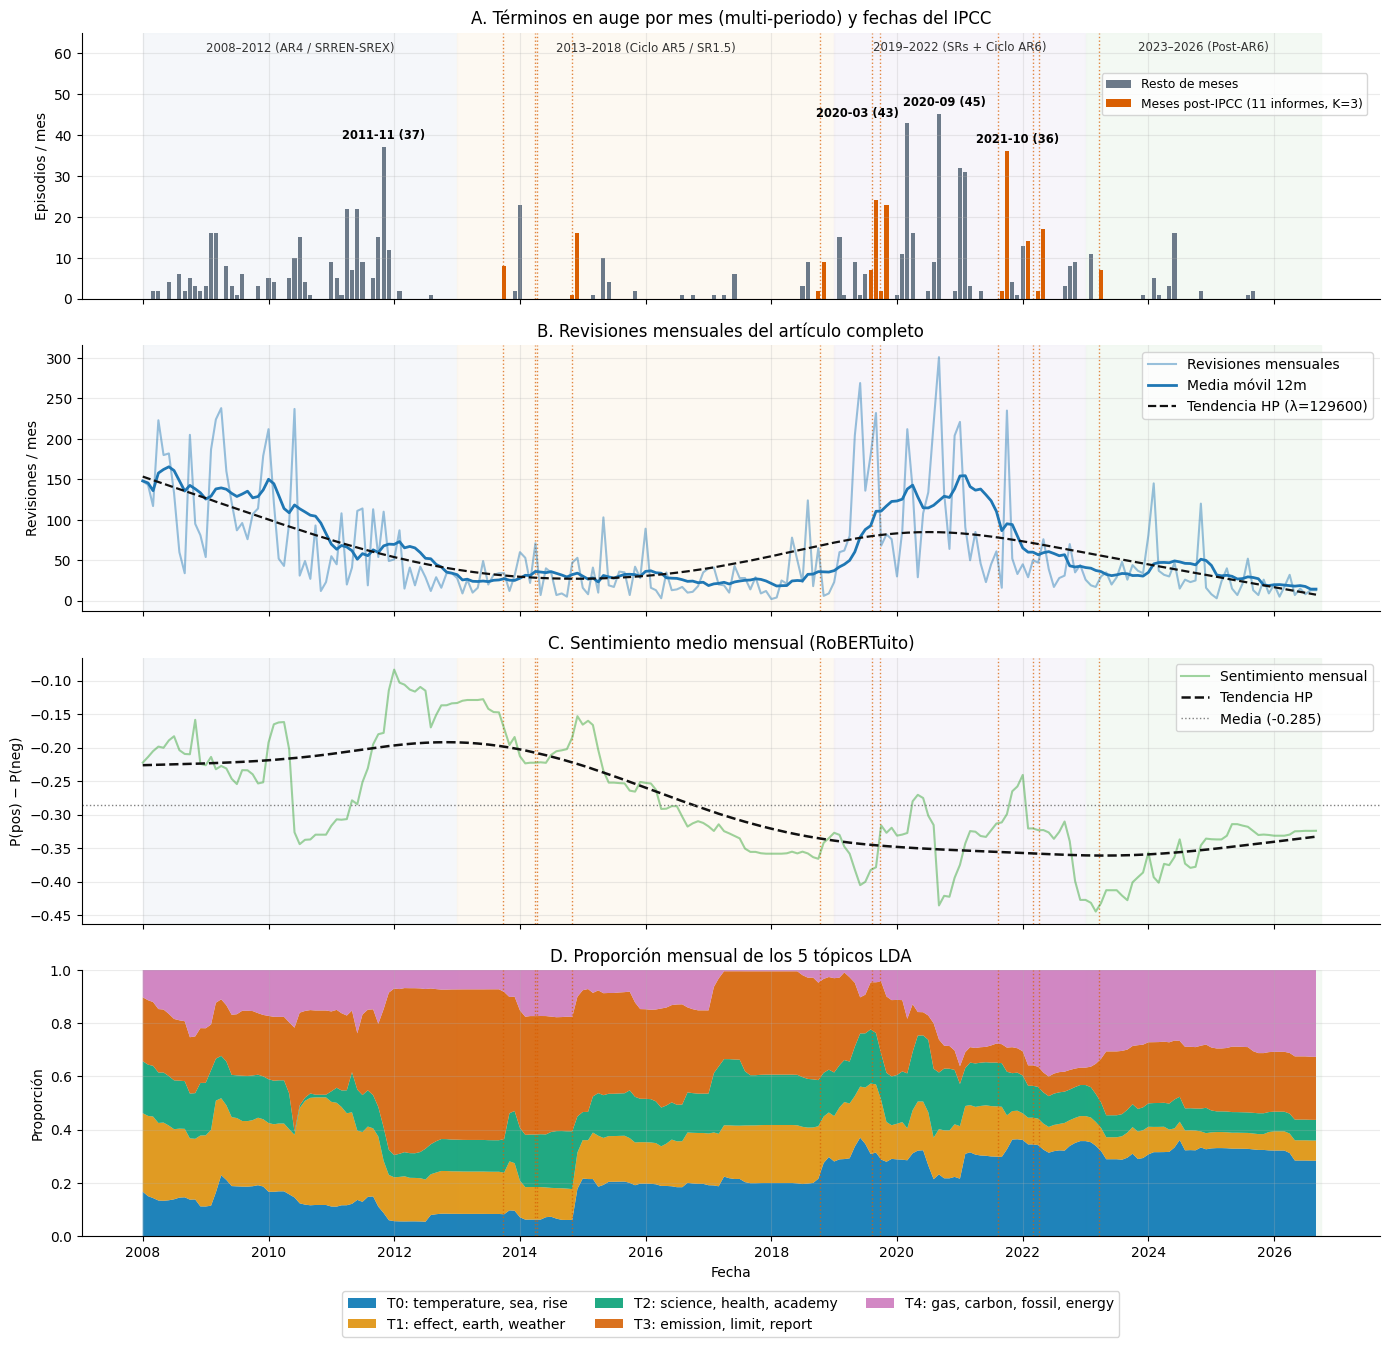

In [7]:
# Gráfico conjunto de los 4 indicadores y los 4 periodos históricos
NOMBRES_TOPICOS = {
    "topico_0": "T0: temperature, sea, rise",
    "topico_1": "T1: effect, earth, weather",
    "topico_2": "T2: science, health, academy",
    "topico_3": "T3: emission, limit, report",
    "topico_4": "T4: gas, carbon, fossil, energy",
}
REGIMENES = [
    ("2008-01-01", "2012-12-31", "2008–2012\n(AR4 / SRREN-SREX)", "#f0f4f8"),
    ("2013-01-01", "2018-12-31", "2013–2018\n(Ciclo AR5 / SR1.5)", "#fdf6ec"),
    ("2019-01-01", "2022-12-31", "2019–2022\n(SRs + Ciclo AR6)", "#f3f0f8"),
    ("2023-01-01", "2026-09-30", "2023–2026\n(Post-AR6)", "#eef6ee"),
]

fig, axes = plt.subplots(4, 1, figsize=(14, 13.5), sharex=True)

for ax in axes:
    for ini, fin, _, color in REGIMENES:
        ax.axvspan(pd.to_datetime(ini), pd.to_datetime(fin), color=color, alpha=0.65, zorder=0)
    for f_ipcc in eventos_e2["fecha"]:
        ax.axvline(f_ipcc, color="#d95f02", linestyle=":", linewidth=1.0, alpha=0.75)

# Panel A: Términos en auge (multi-periodo)
mask_post = df_m["post_ipcc_11"] == 1
axes[0].bar(df_m.index[~mask_post], df_m.loc[~mask_post, "terminos_en_auge_multi"], width=24, color="#6c7a89", label="Resto de meses")
axes[0].bar(df_m.index[mask_post], df_m.loc[mask_post, "terminos_en_auge_multi"], width=24, color="#d95f02", label="Meses post-IPCC (11 informes, K=3)")
top_anot = [
    ("2011-11-01", (0, 6)),
    ("2020-03-01", (-36, 4)),
    ("2020-09-01", (4, 6)),
    ("2021-10-01", (8, 6)),
]
for mes_pico, off in top_anot:
    val = int(df_m.loc[mes_pico, "terminos_en_auge_multi"])
    axes[0].annotate(
        f"{mes_pico[:7]} ({val})",
        xy=(pd.to_datetime(mes_pico), val),
        xytext=off,
        textcoords="offset points",
        ha="center",
        fontsize=8.3,
        fontweight="bold",
    )
ymax_auge = int(df_m["terminos_en_auge_multi"].max()) + 20
for ini, fin, etiq, _ in REGIMENES:
    mid = pd.to_datetime(ini) + (pd.to_datetime(fin) - pd.to_datetime(ini)) / 2
    axes[0].text(mid, ymax_auge - 2.0, etiq.replace("\n", " "), ha="center", va="top", fontsize=8.5, color="#333333")
axes[0].set_ylim(0, ymax_auge)
axes[0].set_ylabel("Episodios / mes")
axes[0].set_title("A. Términos en auge por mes (multi-periodo) y fechas del IPCC")
axes[0].legend(loc="upper right", bbox_to_anchor=(0.995, 0.87), frameon=True, fontsize=8.8)

# Panel B: Revisiones mensuales y tendencia HP
ciclo_rev, tend_rev = hpfilter(df_m["revisiones_total"], lamb=129600)
axes[1].plot(df_m.index, df_m["revisiones_total"], alpha=0.45, color="#1f77b4", label="Revisiones mensuales")
axes[1].plot(df_m.index, df_m["revisiones_total"].rolling(12, min_periods=1).mean(), color="#1f77b4", linewidth=2, label="Media móvil 12m")
axes[1].plot(df_m.index, tend_rev, color="#111111", linestyle="--", linewidth=1.6, label="Tendencia HP (λ=129600)")
axes[1].set_ylabel("Revisiones / mes")
axes[1].set_title("B. Revisiones mensuales del artículo completo")
axes[1].legend(loc="upper right")

# Panel C: Sentimiento medio y tendencia HP
_, tend_sent = hpfilter(df_m["sent_medio"], lamb=129600)
axes[2].plot(df_m.index, df_m["sent_medio"], alpha=0.45, color="#2ca02c", label="Sentimiento mensual")
axes[2].plot(df_m.index, tend_sent, color="#111111", linestyle="--", linewidth=1.8, label="Tendencia HP")
axes[2].axhline(df_m["sent_medio"].mean(), color="grey", linestyle=":", linewidth=1, label=f"Media ({df_m['sent_medio'].mean():.3f})")
axes[2].set_ylabel("P(pos) − P(neg)")
axes[2].set_title("C. Sentimiento medio mensual (RoBERTuito)")
axes[2].legend(loc="upper right")

# Panel D: Tópicos LDA
cols_top = [f"topico_{i}" for i in range(5)]
axes[3].stackplot(
    df_m.index,
    [df_m[c] for c in cols_top],
    labels=[NOMBRES_TOPICOS[c] for c in cols_top],
    alpha=0.88,
)
axes[3].set_ylim(0, 1)
axes[3].set_ylabel("Proporción")
axes[3].set_xlabel("Fecha")
axes[3].set_title("D. Proporción mensual de los 5 tópicos LDA")
axes[3].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=True)
axes[3].xaxis.set_major_locator(mdates.YearLocator(2))
axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.tight_layout()
fig.savefig(RESULTS_DIR / "01_evolucion_indicadores_y_periodos.png", dpi=200, bbox_inches="tight")
plt.show()


In [8]:
# Tests de estacionariedad (ADF), autocorrelación (Ljung-Box) y estacionalidad mensual (Kruskal-Wallis)
cols_analisis = [
    "terminos_en_auge_multi", "terminos_nuevos_multi", "terminos_en_auge_e2",
    "revisiones_total", "revisiones_por_semana",
    "sent_medio", "topico_0", "topico_1", "topico_2", "topico_3", "topico_4",
    "co2_ppm", "temp_anomaly_c", "oni_anomaly", "brent_price", "rev_size",
]

filas_diag = []
for col in cols_analisis:
    s = df_m[col].dropna()
    adf_lvl = adfuller(s, autolag="AIC")
    adf_d1 = adfuller(s.diff().dropna(), autolag="AIC")
    lb = acorr_ljungbox(s, lags=[1, 12], return_df=True)
    grupos_mes = [s[s.index.month == m].to_numpy() for m in range(1, 13)]
    kw_stat, kw_p = stats.kruskal(*grupos_mes)
    dec = seasonal_decompose(s, model="additive", period=12)
    var_res = float(np.var(dec.resid.dropna()))
    var_des = float(np.var((s - dec.trend).dropna()))
    fuerza_est = max(0.0, 1.0 - var_res / var_des) if var_des > 0 else 0.0
    filas_diag.append({
        "serie": col,
        "media": round(float(s.mean()), 3),
        "mediana": round(float(s.median()), 3),
        "desv_tip": round(float(s.std()), 3),
        "pct_ceros": round(float((s == 0).mean() * 100), 1),
        "ADF_stat_nivel": round(float(adf_lvl[0]), 3),
        "ADF_p_nivel": round(float(adf_lvl[1]), 4),
        "ADF_p_diff1": round(float(adf_d1[1]), 4),
        "LB_p_lag1": round(float(lb.loc[1, "lb_pvalue"]), 4),
        "LB_p_lag12": round(float(lb.loc[12, "lb_pvalue"]), 4),
        "KW_estacional_p": round(float(kw_p), 4),
        "fuerza_estacional": round(fuerza_est, 3),
    })

diag_df = pd.DataFrame(filas_diag)
diag_df.to_csv(RESULTS_DIR / "estacionariedad_y_estacionalidad.csv", index=False)
display(diag_df)


,serie,media,mediana,desv_tip,pct_ceros,ADF_stat_nivel,ADF_p_nivel,ADF_p_diff1,LB_p_lag1,LB_p_lag12,KW_estacional_p,fuerza_estacional
0,terminos_en_auge_multi,3.627,0.000,7.558,57.3,-3.413,0.0105,0.0000,0.0002,0.0,0.8053,0.038
1,terminos_nuevos_multi,1.920,0.000,4.253,64.9,-4.458,0.0002,0.0000,0.0001,0.0,0.7986,0.036
2,terminos_en_auge_e2,2.640,0.000,5.664,60.0,-3.555,0.0067,0.0000,0.0002,0.0,0.7977,0.035
3,revisiones_total,59.862,35.000,60.852,0.0,-1.656,0.4541,0.0000,0.0000,0.0,0.9826,0.023
4,revisiones_por_semana,13.824,8.250,14.074,0.0,-1.711,0.4253,0.0000,0.0000,0.0,0.9823,0.023
5,sent_medio,-0.285,-0.315,0.085,0.0,-2.309,0.1691,0.0000,0.0000,0.0,0.9999,0.068
6,topico_0,0.214,0.200,0.094,0.0,-1.282,0.6375,0.0000,0.0000,0.0,1.0000,0.051
7,topico_1,0.175,0.170,0.080,0.0,-2.124,0.2348,0.0000,0.0000,0.0,1.0000,0.051
8,topico_2,0.142,0.150,0.054,0.0,-2.986,0.0362,0.0000,0.0000,0.0,1.0000,0.036
9,topico_3,0.293,0.246,0.143,0.0,-1.898,0.3328,0.0000,0.0000,0.0,1.0000,0.013


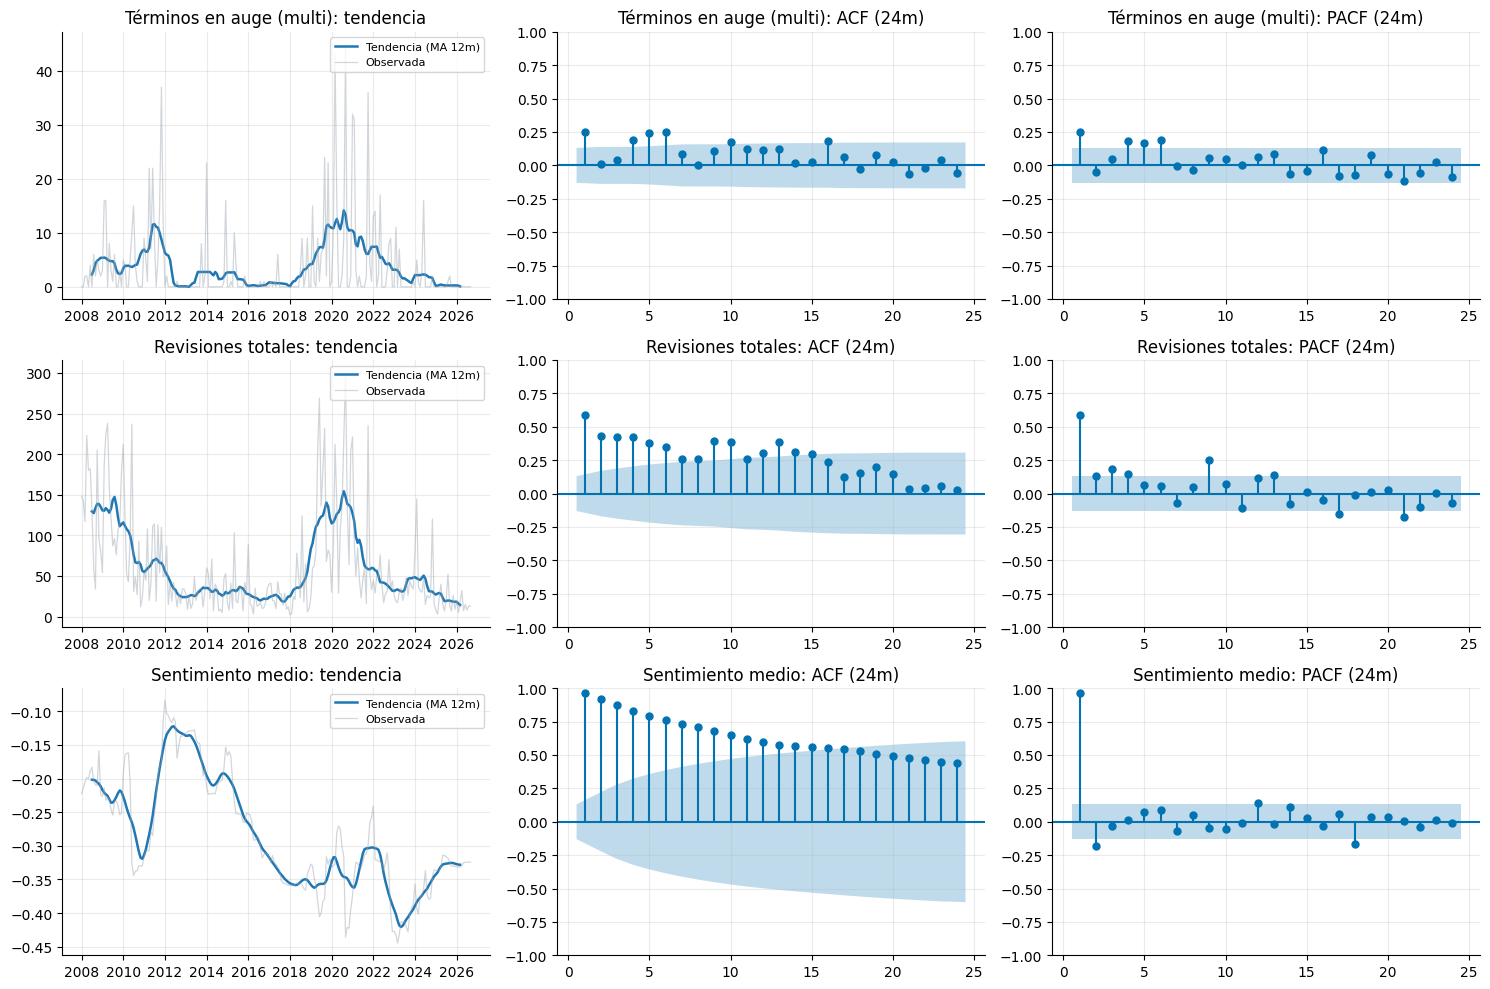

In [9]:
# Descomposición de tendencia y gráficos ACF / PACF de los tres indicadores principales
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
series_diag = [
    ("terminos_en_auge_multi", "Términos en auge (multi)"),
    ("revisiones_total", "Revisiones totales"),
    ("sent_medio", "Sentimiento medio"),
]

for fila, (col, titulo) in enumerate(series_diag):
    s = df_m[col]
    dec = seasonal_decompose(s, model="additive", period=12)
    axes[fila, 0].plot(s.index, dec.trend, color="#1f77b4", linewidth=1.8, label="Tendencia (MA 12m)")
    axes[fila, 0].plot(s.index, s, color="#9aa5b1", alpha=0.45, linewidth=0.9, label="Observada")
    axes[fila, 0].set_title(f"{titulo}: tendencia")
    axes[fila, 0].legend(loc="upper right", fontsize=8)

    plot_acf(s, lags=24, ax=axes[fila, 1], zero=False, title=f"{titulo}: ACF (24m)")
    plot_pacf(s, lags=24, ax=axes[fila, 2], zero=False, method="ywm", title=f"{titulo}: PACF (24m)")

fig.tight_layout()
fig.savefig(RESULTS_DIR / "02_descomposicion_acf_pacf.png", dpi=200, bbox_inches="tight")
plt.show()


**Resumen de la exploración temporal:**
- **`terminos_en_auge_multi`:** es estacionaria en niveles (`ADF = -3,413`, `p = 0,0105`), con media `3,627` episodios/mes, desviación típica `7,558` y mediana `0,0` (`57,3 %` de meses en cero). Tiene autocorrelación a corto plazo (`Ljung-Box lag 1 p = 0,0002`, `PACF(1) = 0,2484`) porque las reescrituras se agrupan en rachas y las ventanas de 12 semanas se solapan. Los mayores picos son `2020-09` (45), `2020-03` (43), `2011-11` (37) y `2021-10` (36).
- **`revisiones_total` y `sent_medio`:** no son estacionarias en niveles (`ADF p = 0,4541` y `p = 0,1691`) porque cambian de nivel entre épocas, pero sí lo son en primera diferencia (`ADF p < 0,0001`). En los tópicos, solo `topico_2` (`p = 0,0362`) es estacionario en niveles.
- **Efecto de la repetición del texto:** como vimos en 2.1, que el `61,15 %` de las semanas y el `19,56 %` de los meses repitan texto explica la caída tan lenta de la ACF y el pico de la PACF en lag 1 en `sent_medio` (`0,9665`) y en `topico_0..4` (`0,9452–0,9815`).
- **Sin estacionalidad anual:** ninguno de los indicadores del artículo sigue un patrón por mes del año (`Kruskal-Wallis p ≥ 0,7977` y fuerza estacional `≤ 0,068`). En cambio, `co2_ppm` sí muestra su ciclo anual habitual (fuerza estacional `0,982`).


---


## **3. Contraste de hipótesis: permutación circular, perfil de rezagos y SARIMAX**

Contrastamos la hipótesis en los **219 meses evaluables** (`2008-04` a `2026-06`, donde hay 12 semanas completas antes y después). Comparamos siempre el **indicador nuevo (`terminos_en_auge_multi`, principal)** con el **original de la Entrega 2 (`terminos_en_auge_e2`)** usando tres métodos:

1. **Test de permutación por desplazamiento circular:** mantiene la autocorrelación y el espaciado entre informes del IPCC, y lo probamos en los 3 calendarios (`11 informes E2`, `13 informes SREX SPM` y `13 informes SREX Completo`) y con ventanas $K \in \{1, 2, 3, 4\}$.
2. **Estudio de eventos (perfil de rezagos):** miramos la media de episodios desde 3 meses antes hasta 5 meses después ($\tau \in [-3, +5]$) de cada informe, y revisamos qué ocurrió exactamente en `2011-11`.
3. **Modelos SARIMAX con variable de intervención (`post_ipcc`):** medimos el efecto de las ventanas del IPCC controlando por el término autorregresivo y por el volumen de ediciones (`log1p(revisiones_total)`).

> **Nota sobre SARIMAX en conteos:** SARIMAX supone errores normales, algo que no encaja del todo bien en series de conteo con muchos ceros (`57,3 %` en `terminos_en_auge_multi`). Por eso ajustamos todos los modelos también sobre `log1p(...)` y comprobamos si coinciden con el test no paramétrico de permutación circular.


In [10]:
# Permutación circular: indicador multi-periodo (principal) vs. Entrega 2 original
df_eval = df_m.loc["2008-04":"2026-06"].copy()

def test_permutacion_circular(valores: np.ndarray, mascara: np.ndarray) -> tuple[float, float, np.ndarray]:
    obs = float(valores[mascara].mean() - valores[~mascara].mean())
    difs = np.array([
        valores[np.roll(mascara, s)].mean() - valores[~np.roll(mascara, s)].mean()
        for s in range(len(mascara))
    ], dtype=float)
    p_val = float(np.mean(difs >= obs - 1e-12))
    return obs, p_val, difs

escenarios = [
    ("Entrega 2 original (11 informes, 2013–2023)", eventos_e2),
    ("Ampliado 2011 (13 informes, SREX SPM nov-2011)", eventos_13_spm),
    ("Ampliado 2011 (13 informes, SREX Completo mar-2012)", eventos_13_full),
]

indicadores_hip = [
    ("terminos_en_auge_multi", "Multi-periodo (principal)"),
    ("terminos_en_auge_e2",    "Entrega 2 original (comparativa)"),
]

filas_hip = []
distribuciones_perm = {}
for col_ind, etiq_ind in indicadores_hip:
    x_eval = df_eval[col_ind].to_numpy(dtype=float)
    for nombre_esc, ev_df in escenarios:
        for k in [1, 2, 3, 4]:
            mascara = construir_mascara_ipcc(df_eval["mes_p"], ev_df, k=k)
            obs, p_val, difs = test_permutacion_circular(x_eval, mascara)
            filas_hip.append({
                "indicador": etiq_ind,
                "columna": col_ind,
                "escenario": nombre_esc,
                "K_meses": k,
                "n_post_ipcc": int(mascara.sum()),
                "media_post": round(float(x_eval[mascara].mean()), 3),
                "media_resto": round(float(x_eval[~mascara].mean()), 3),
                "mediana_post": round(float(np.median(x_eval[mascara])), 2),
                "mediana_resto": round(float(np.median(x_eval[~mascara])), 2),
                "diferencia_medias": round(obs, 3),
                "p_perm_circular": round(p_val, 4),
            })
            if k == 3:
                distribuciones_perm[(col_ind, nombre_esc)] = (obs, p_val, difs)

hip_df = pd.DataFrame(filas_hip)
hip_df.to_csv(RESULTS_DIR / "contraste_hipotesis_ipcc.csv", index=False)

print("Comparativa K=3 meses (multi-periodo vs. Entrega 2):")
display(hip_df[hip_df["K_meses"] == 3][["indicador", "escenario", "n_post_ipcc", "media_post", "media_resto", "mediana_post", "mediana_resto", "diferencia_medias", "p_perm_circular"]])

print("\nSensibilidad según ventana K (1 a 4 meses) en multi-periodo:")
display(hip_df[hip_df["columna"] == "terminos_en_auge_multi"][["escenario", "K_meses", "n_post_ipcc", "diferencia_medias", "p_perm_circular"]])


Comparativa K=3 meses (multi-periodo vs. Entrega 2):


,indicador,escenario,n_post_ipcc,media_post,media_resto,mediana_post,mediana_resto,diferencia_medias,p_perm_circular
2,Multi-periodo (principal),"Entrega 2 original (11 informes, 2013–2023)",28,6.071,3.372,1.5,0.0,2.700,0.1324
6,Multi-periodo (principal),"Ampliado 2011 (13 informes, SREX SPM nov-2011)",34,7.559,3.011,2.0,0.0,4.548,0.0137
10,Multi-periodo (principal),"Ampliado 2011 (13 informes, SREX Completo mar-...",34,6.118,3.276,1.5,0.0,2.842,0.1142
14,Entrega 2 original (comparativa),"Entrega 2 original (11 informes, 2013–2023)",28,4.143,2.492,1.0,0.0,1.651,0.1826
18,Entrega 2 original (comparativa),"Ampliado 2011 (13 informes, SREX SPM nov-2011)",34,5.529,2.184,1.5,0.0,3.346,0.0137
22,Entrega 2 original (comparativa),"Ampliado 2011 (13 informes, SREX Completo mar-...",34,4.353,2.400,1.0,0.0,1.953,0.1279



Sensibilidad según ventana K (1 a 4 meses) en multi-periodo:


,escenario,K_meses,n_post_ipcc,diferencia_medias,p_perm_circular
0,"Entrega 2 original (11 informes, 2013–2023)",1,11,0.872,0.3105
1,"Entrega 2 original (11 informes, 2013–2023)",2,20,2.017,0.1963
2,"Entrega 2 original (11 informes, 2013–2023)",3,28,2.700,0.1324
3,"Entrega 2 original (11 informes, 2013–2023)",4,36,1.403,0.2740
4,"Ampliado 2011 (13 informes, SREX SPM nov-2011)",1,13,3.736,0.0913
5,"Ampliado 2011 (13 informes, SREX SPM nov-2011)",2,24,4.670,0.0228
6,"Ampliado 2011 (13 informes, SREX SPM nov-2011)",3,34,4.548,0.0137
7,"Ampliado 2011 (13 informes, SREX SPM nov-2011)",4,44,2.886,0.0868
8,"Ampliado 2011 (13 informes, SREX Completo mar-...",1,13,0.710,0.3059
9,"Ampliado 2011 (13 informes, SREX Completo mar-...",2,24,2.377,0.1689


,escenario,tau_meses,n_meses,media_auge_multi,error_est_auge_multi,mediana_auge_multi,media_auge_e2,media_revisiones
0,"Entrega 2 original (11 informes, 2013–2023)",-3,11,5.182,2.169,2.0,3.818,75.5
1,"Entrega 2 original (11 informes, 2013–2023)",-2,11,4.909,2.294,1.0,3.000,71.1
2,"Entrega 2 original (11 informes, 2013–2023)",-1,11,3.364,1.509,0.0,2.000,55.0
3,"Entrega 2 original (11 informes, 2013–2023)",0,11,4.545,2.341,1.0,2.909,73.2
4,"Entrega 2 original (11 informes, 2013–2023)",1,11,7.727,2.461,7.0,5.091,58.5
5,"Entrega 2 original (11 informes, 2013–2023)",2,11,5.727,3.658,0.0,4.182,53.6
6,"Entrega 2 original (11 informes, 2013–2023)",3,11,4.182,2.423,0.0,3.364,41.8
7,"Entrega 2 original (11 informes, 2013–2023)",4,11,3.727,2.344,0.0,2.455,39.8
8,"Entrega 2 original (11 informes, 2013–2023)",5,11,2.636,1.429,0.0,1.909,36.3



Noviembre 2011: 37 episodios multi-periodo (28 en E2).
Fechas con cambios en nov-2011: ['2011-11-06', '2011-11-13', '2011-11-20', '2011-11-27'] (SREX SPM salió el 2011-11-18)
Principales términos en 2011-11: ['synthesis', 'section', 'uncertainty', 'observation', 'projections', 'assess', 'chap', 'meehl', 'summary', 'analysis', 'project', 'continuation']


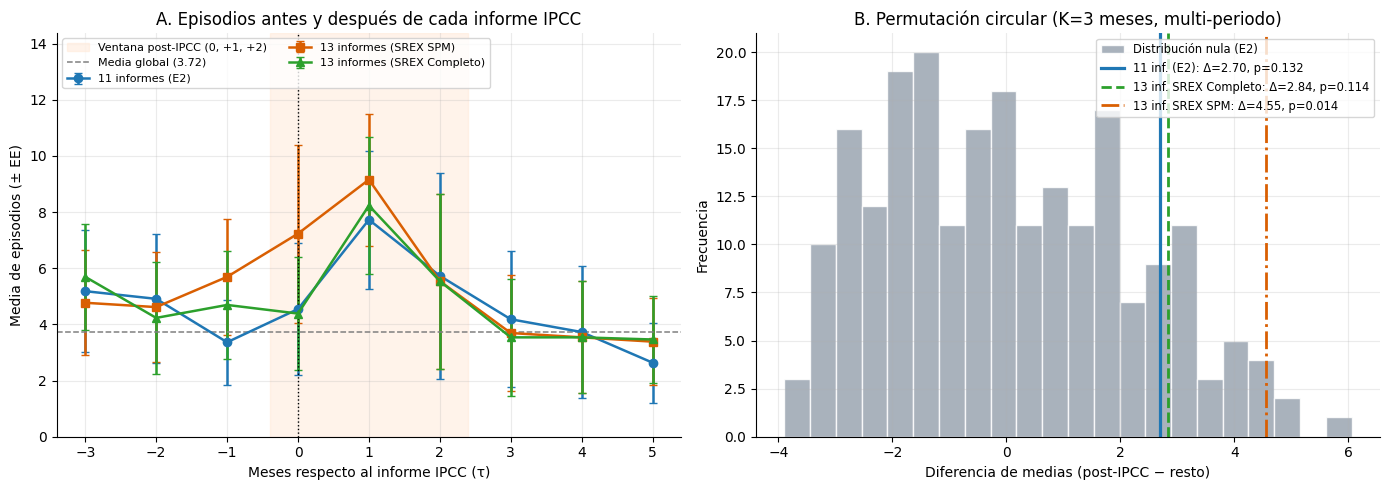

In [11]:
# Perfil de rezagos tau en [-3, +5] alrededor de cada informe IPCC y revisión de 2011-11
filas_tau = []
for nombre_esc, ev_df in escenarios:
    ev_meses = ev_df["mes"].tolist()
    for tau in range(-3, 6):
        meses_tau = {e + tau for e in ev_meses}
        sub = df_eval[df_eval["mes_p"].isin(meses_tau)]
        filas_tau.append({
            "escenario": nombre_esc,
            "tau_meses": tau,
            "n_meses": len(sub),
            "media_auge_multi": round(float(sub["terminos_en_auge_multi"].mean()), 3),
            "error_est_auge_multi": round(float(sub["terminos_en_auge_multi"].std(ddof=1) / np.sqrt(len(sub))), 3),
            "mediana_auge_multi": round(float(sub["terminos_en_auge_multi"].median()), 2),
            "media_auge_e2": round(float(sub["terminos_en_auge_e2"].mean()), 3),
            "media_revisiones": round(float(sub["revisiones_total"].mean()), 1),
        })

tau_df = pd.DataFrame(filas_tau)
tau_df.to_csv(RESULTS_DIR / "perfil_rezagos_ipcc.csv", index=False)
display(tau_df[tau_df["escenario"].str.contains("original")])

# Revisamos qué pasó exactamente en noviembre de 2011
top_2011_11 = auge_multi[auge_multi["mes"] == "2011-11"].sort_values("salto", ascending=False)
cambios_nov11 = serie_w[(serie_w["mes"] == "2011-11") & (serie_w["texto_nuevo"])]["timestamp"].dt.strftime("%Y-%m-%d").tolist()
print(f"\nNoviembre 2011: {len(top_2011_11)} episodios multi-periodo ({int(df_eval.loc['2011-11-01', 'terminos_en_auge_e2'])} en E2).")
print("Fechas con cambios en nov-2011:", cambios_nov11, "(SREX SPM salió el 2011-11-18)")
print("Principales términos en 2011-11:", top_2011_11["termino"].head(12).tolist())

# Gráfico 03: Perfil de rezagos y distribución de permutación circular
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

base_media = float(df_eval["terminos_en_auge_multi"].mean())
etiquetas_cortas = {
    "Entrega 2 original (11 informes, 2013–2023)": "11 informes (E2)",
    "Ampliado 2011 (13 informes, SREX SPM nov-2011)": "13 informes (SREX SPM)",
    "Ampliado 2011 (13 informes, SREX Completo mar-2012)": "13 informes (SREX Completo)",
}
for nombre_esc, color, marker in [
    ("Entrega 2 original (11 informes, 2013–2023)", "#1f77b4", "o"),
    ("Ampliado 2011 (13 informes, SREX SPM nov-2011)", "#d95f02", "s"),
    ("Ampliado 2011 (13 informes, SREX Completo mar-2012)", "#2ca02c", "^"),
]:
    sub_t = tau_df[tau_df["escenario"] == nombre_esc]
    axes[0].errorbar(
        sub_t["tau_meses"], sub_t["media_auge_multi"], yerr=sub_t["error_est_auge_multi"],
        marker=marker, capsize=3, linewidth=1.8, label=etiquetas_cortas[nombre_esc], color=color,
    )
axes[0].axvspan(-0.4, 2.4, color="#ffe8d6", alpha=0.5, label="Ventana post-IPCC (0, +1, +2)")
axes[0].axhline(base_media, color="grey", linestyle="--", linewidth=1.1, label=f"Media global ({base_media:.2f})")
axes[0].axvline(0, color="black", linestyle=":", linewidth=1.0)
axes[0].set_xticks(range(-3, 6))
ymax_tau = float((tau_df["media_auge_multi"] + tau_df["error_est_auge_multi"]).max()) * 1.25
axes[0].set_ylim(0, ymax_tau)
axes[0].set_xlabel("Meses respecto al informe IPCC (τ)")
axes[0].set_ylabel("Media de episodios (± EE)")
axes[0].set_title("A. Episodios antes y después de cada informe IPCC")
axes[0].legend(loc="upper left", ncol=2, fontsize=8.0)

# Panel B: Distribución nula de permutación circular
obs_e2, p_e2, difs_e2 = distribuciones_perm[("terminos_en_auge_multi", "Entrega 2 original (11 informes, 2013–2023)")]
obs_spm, p_spm, _ = distribuciones_perm[("terminos_en_auge_multi", "Ampliado 2011 (13 informes, SREX SPM nov-2011)")]
obs_full, p_full, _ = distribuciones_perm[("terminos_en_auge_multi", "Ampliado 2011 (13 informes, SREX Completo mar-2012)")]

axes[1].hist(difs_e2, bins=22, color="#9aa5b1", edgecolor="white", alpha=0.85, label="Distribución nula (E2)")
axes[1].axvline(obs_e2, color="#1f77b4", linewidth=2.3, label=f"11 inf. (E2): Δ={obs_e2:.2f}, p={p_e2:.3f}")
axes[1].axvline(obs_full, color="#2ca02c", linewidth=2.0, linestyle="--", label=f"13 inf. SREX Completo: Δ={obs_full:.2f}, p={p_full:.3f}")
axes[1].axvline(obs_spm, color="#d95f02", linewidth=2.0, linestyle="-.", label=f"13 inf. SREX SPM: Δ={obs_spm:.2f}, p={p_spm:.3f}")
axes[1].set_xlabel("Diferencia de medias (post-IPCC − resto)")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title("B. Permutación circular (K=3 meses, multi-periodo)")
axes[1].legend(loc="upper right", fontsize=8.3)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "03_contraste_hipotesis_ipcc.png", dpi=200, bbox_inches="tight")
plt.show()


In [12]:
# Modelos SARIMAX con intervención post_ipcc (multi-periodo principal + Entrega 2 comparativa)
df_eval["log_auge_multi"] = np.log1p(df_eval["terminos_en_auge_multi"])
df_eval["log_auge_e2"] = np.log1p(df_eval["terminos_en_auge_e2"])
df_eval["log_rev"] = np.log1p(df_eval["revisiones_total"])

especificaciones_sarimax = [
    ("terminos_en_auge_multi", "Multi | Solo ARMA(1,0,0) (sin exógena)", (1, 0, 0), None),
    ("terminos_en_auge_multi", "Multi | SARIMAX(1,0,0) + post_ipcc_11 (E2)", (1, 0, 0), ["post_ipcc_11"]),
    ("terminos_en_auge_multi", "Multi | SARIMAX(1,0,0) + post_ipcc_11 + log_rev", (1, 0, 0), ["post_ipcc_11", "log_rev"]),
    ("terminos_en_auge_multi", "Multi | SARIMAX(1,0,0) + post_ipcc_13_spm", (1, 0, 0), ["post_ipcc_13_spm"]),
    ("terminos_en_auge_multi", "Multi | SARIMAX(1,0,0) + post_ipcc_13_full", (1, 0, 0), ["post_ipcc_13_full"]),
    ("log_auge_multi",         "Multi log1p | Solo ARMA(1,0,0)", (1, 0, 0), None),
    ("log_auge_multi",         "Multi log1p | SARIMAX(1,0,0) + post_ipcc_11", (1, 0, 0), ["post_ipcc_11"]),
    ("log_auge_multi",         "Multi log1p | SARIMAX(1,0,0) + post_ipcc_11 + log_rev", (1, 0, 0), ["post_ipcc_11", "log_rev"]),
    ("log_auge_multi",         "Multi log1p | SARIMAX(1,0,0) + post_ipcc_13_spm", (1, 0, 0), ["post_ipcc_13_spm"]),
    ("log_auge_multi",         "Multi log1p | SARIMAX(1,0,0) + post_ipcc_13_full", (1, 0, 0), ["post_ipcc_13_full"]),
    ("terminos_en_auge_e2",    "E2 orig | SARIMAX(1,0,0) + post_ipcc_11", (1, 0, 0), ["post_ipcc_11"]),
    ("terminos_en_auge_e2",    "E2 orig | SARIMAX(1,0,0) + post_ipcc_13_spm", (1, 0, 0), ["post_ipcc_13_spm"]),
    ("terminos_en_auge_e2",    "E2 orig | SARIMAX(1,0,0) + post_ipcc_13_full", (1, 0, 0), ["post_ipcc_13_full"]),
    ("log_auge_e2",            "E2 log1p | SARIMAX(1,0,0) + post_ipcc_11", (1, 0, 0), ["post_ipcc_11"]),
    ("log_auge_e2",            "E2 log1p | SARIMAX(1,0,0) + post_ipcc_13_spm", (1, 0, 0), ["post_ipcc_13_spm"]),
    ("log_auge_e2",            "E2 log1p | SARIMAX(1,0,0) + post_ipcc_13_full", (1, 0, 0), ["post_ipcc_13_full"]),
    ("log_rev",                "Volumen | Solo ARMA(1,0,1) sobre log1p(revisiones)", (1, 0, 1), None),
    ("log_rev",                "Volumen | SARIMAX(1,0,1) log1p(rev) + post_ipcc_11", (1, 0, 1), ["post_ipcc_11"]),
    ("log_rev",                "Volumen | SARIMAX(1,0,1) log1p(rev) + post_ipcc_13_spm", (1, 0, 1), ["post_ipcc_13_spm"]),
]

filas_sarimax = []
for y_col, desc, orden, ex_cols in especificaciones_sarimax:
    X = df_eval[ex_cols] if ex_cols else None
    ajuste = SARIMAX(df_eval[y_col], exog=X, order=orden, trend="c").fit(disp=False)
    lb_res = acorr_ljungbox(ajuste.resid, lags=[12], return_df=True)
    var_ipcc = ex_cols[0] if ex_cols else "-"
    beta_ipcc = float(ajuste.params[var_ipcc]) if ex_cols else np.nan
    p_ipcc = float(ajuste.pvalues[var_ipcc]) if ex_cols else np.nan
    beta_rev = float(ajuste.params["log_rev"]) if (ex_cols and "log_rev" in ex_cols) else np.nan
    p_rev = float(ajuste.pvalues["log_rev"]) if (ex_cols and "log_rev" in ex_cols) else np.nan
    filas_sarimax.append({
        "serie_objetivo": y_col,
        "modelo": desc,
        "beta_post_ipcc": None if np.isnan(beta_ipcc) else round(beta_ipcc, 4),
        "p_post_ipcc": None if np.isnan(p_ipcc) else round(p_ipcc, 4),
        "beta_log_rev": None if np.isnan(beta_rev) else round(beta_rev, 4),
        "p_log_rev": None if np.isnan(p_rev) else round(p_rev, 4),
        "AIC": round(float(ajuste.aic), 2),
        "BIC": round(float(ajuste.bic), 2),
        "LB_res_p_lag12": round(float(lb_res.loc[12, "lb_pvalue"]), 4),
    })

sarimax_hip_df = pd.DataFrame(filas_sarimax)
sarimax_hip_df.to_csv(RESULTS_DIR / "sarimax_intervencion_hipotesis.csv", index=False)
display(sarimax_hip_df)


,serie_objetivo,modelo,beta_post_ipcc,p_post_ipcc,beta_log_rev,p_log_rev,AIC,BIC,LB_res_p_lag12
0,terminos_en_auge_multi,"Multi | Solo ARMA(1,0,0) (sin exógena)",NaN,NaN,NaN,NaN,1503.63,1513.79,0.0049
1,terminos_en_auge_multi,"Multi | SARIMAX(1,0,0) + post_ipcc_11 (E2)",2.7564,0.0978,NaN,NaN,1503.12,1516.67,0.0055
2,terminos_en_auge_multi,"Multi | SARIMAX(1,0,0) + post_ipcc_11 + log_rev",2.6025,0.0555,3.4692,0.0,1465.67,1482.62,0.1219
3,terminos_en_auge_multi,"Multi | SARIMAX(1,0,0) + post_ipcc_13_spm",4.2620,0.0010,NaN,NaN,1498.39,1511.95,0.0053
4,terminos_en_auge_multi,"Multi | SARIMAX(1,0,0) + post_ipcc_13_full",2.6554,0.0962,NaN,NaN,1502.85,1516.41,0.0138
5,log_auge_multi,"Multi log1p | Solo ARMA(1,0,0)",NaN,NaN,NaN,NaN,638.00,648.17,0.0069
6,log_auge_multi,"Multi log1p | SARIMAX(1,0,0) + post_ipcc_11",0.3437,0.1372,NaN,NaN,638.18,651.73,0.0074
7,log_auge_multi,"Multi log1p | SARIMAX(1,0,0) + post_ipcc_11 + ...",0.3561,0.0432,0.5750,0.0,587.54,604.49,0.8278
8,log_auge_multi,"Multi log1p | SARIMAX(1,0,0) + post_ipcc_13_spm",0.5234,0.0124,NaN,NaN,634.97,648.53,0.0074
9,log_auge_multi,"Multi log1p | SARIMAX(1,0,0) + post_ipcc_13_full",0.3534,0.1056,NaN,NaN,637.69,651.25,0.0140


**Lectura de los resultados del contraste (Sección 3):**
- **Multi-periodo frente a Entrega 2 original:** al recuperar los 222 episodios que antes se perdían, la diferencia de medias en el escenario base de 11 informes ($K = 3$) sube de $\Delta = 1{,}651$ (`p = 0,1826`) a $\Delta = 2{,}700$ episodios/mes (`6,071` frente a `3,372`; mediana `1,5` frente a `0,0`) y el p-valor baja a **`p = 0,1324`**. Aun así, sigue sin ser significativo ($p > 0{,}05$) en ninguna ventana $K \in \{1, 2, 3, 4\}$ (`p` entre `0,1324` y `0,3105`).
- **Sensibilidad a `SREX SPM (nov-2011)` vs. `SREX Completo (mar-2012)`:** si fechamos SREX en su SPM (`2011-11-18`), la diferencia sube a $\Delta = 4{,}548$ y sale significativa (**`p = 0,0137`**, igual que en E2). Pero si usamos la publicación del informe completo (`2012-03-28`), el resultado vuelve a no ser significativo ($\Delta = 2{,}842$, **`p = 0,1142`** en multi-periodo; $\Delta = 1{,}953$, `p = 0,1279` en E2).
- **Qué pasó en `2011-11`:** al revisar las ediciones de ese mes en `dataset_clean.parquet`, vemos que el salto de 37 episodios empezó el **`2011-11-06` y el `2011-11-13`**, es decir, hasta 12 días **antes** de que saliera el SREX SPM (`2011-11-18`). Además, las palabras que entran (`synthesis`, `section`, `uncertainty`, `observation`, `projections`, `assess`, `chap`, `meehl`, `summary`) vienen de añadir referencias del **AR4 de 2007** (capítulo de Meehl et al.), no del SREX. Por eso el positivo del escenario `13_spm` se debe a una coincidencia de fechas.
- **Qué dicen los modelos SARIMAX:**
  - Sin controlar por volumen de revisiones, `post_ipcc_11` no es significativo ni en niveles ($\beta = 2{,}7564$, `p = 0,0978`, BIC sube de `1513,79` a `1516,67`) ni en `log1p` ($\beta = 0{,}3437$, `p = 0,1372`). Lo mismo pasa con `post_ipcc_13_full` (`p = 0,0962` en niveles; `p = 0,1056` en `log1p`). Tampoco el volumen de revisiones cambia en las ventanas del IPCC (`log_rev` + `post_ipcc_11`: `p = 0,7872`; `post_ipcc_13_spm`: `p = 0,3735`).
  - Al añadir `log_rev` como control, esta variable explica gran parte de la serie ($\beta = 0{,}5750$, `p < 0,0001` en `log1p`, el AIC baja 50,6 puntos y los residuos pasan Ljung-Box con `p = 0,8278`). En ese ajuste, `post_ipcc_11` roza el 5 % en `log1p` ($\beta = 0{,}3561$, `p = 0,0432`; en niveles `p = 0,0555`). Junto al pico en $\tau = +1$ (`7,727` episodios/mes, mediana `7,0`, tirado sobre todo por `SROCC 2019` y `AR6 WGI 2021`), vemos un efecto parcial en informes sueltos, pero no una respuesta general que nos permita rechazar $H_0$.


---


## **4. Modelado y predicción: SARIMAX, Suavizado Exponencial y RNN (LSTM)**

Comparamos las tres familias de modelos de clase (SARIMAX, Suavizado Exponencial y LSTM) junto a varios baselines sencillos. Usamos siempre partición cronológica (sin mezclar futuro con entrenamiento) y elegimos el orden SARIMA solo por AIC en entrenamiento:

1. **`revisiones_total`:** test con los últimos 24 meses completos (`2024-09` a `2026-08`; quitamos `2008-01` y `2026-09` por ser meses parciales), entrenando sobre `log1p`. Evaluamos a **1 paso** y a **24 meses**, y luego proyectamos los 12 meses siguientes (`2026-09` a `2027-08`) con el orden ganador reentrenado sobre toda la serie.
2. **`sent_medio`:** mismo test de 24 meses (`2024-09` a `2026-08`) y misma proyección de 12 meses (`2026-09` a `2027-08`).
3. **`terminos_en_auge_multi`:** test en `2021-01` a `2024-12` (48 meses que incluyen los 4 informes de AR6, ya que en `2025–2026` casi no hay episodios) para ver si añadir `post_ipcc` mejora las predicciones frente a SARIMA sin exógena, SES, LSTM y los baselines. Como SARIMAX asume errores normales en una serie con muchos ceros, probamos también la versión sobre `log1p`.

En las tres series comprobamos además con **Ljung-Box (`lag = 12`)** si los residuos se comportan como ruido blanco.


In [13]:
# Funciones comunes para evaluar SARIMA/SARIMAX, Suavizado Exponencial y LSTM
def calcular_metricas(y_real: np.ndarray, y_pred: np.ndarray, serie: str, modelo: str, modo: str) -> dict:
    return {
        "serie": serie,
        "modo": modo,
        "modelo": modelo,
        "MAE": round(float(mean_absolute_error(y_real, y_pred)), 4),
        "RMSE": round(float(root_mean_squared_error(y_real, y_pred)), 4),
    }


def entrenar_y_predecir_lstm(
    train_s: pd.Series,
    full_s: pd.Series,
    seq_len: int = 12,
    hidden: int = 16,
    epochs: int = 250,
    lr: float = 0.005,
    log_transform: bool = False,
    differenced: bool = False,
) -> tuple[np.ndarray, np.ndarray]:
    """Entrena un LSTM de 1 capa solo en train y devuelve pronóstico multi-paso y 1-paso."""
    torch.manual_seed(SEED)
    np.random.seed(SEED)

    base = np.log1p(full_s.to_numpy(float)) if log_transform else full_s.to_numpy(float)
    n_tr = len(train_s)
    n_te = len(full_s) - n_tr

    vals = np.diff(base) if differenced else base
    n_tr_seq = n_tr - 1 if differenced else n_tr

    scaler = StandardScaler()
    tr_sc = scaler.fit_transform(vals[:n_tr_seq].reshape(-1, 1)).ravel()
    all_sc = scaler.transform(vals.reshape(-1, 1)).ravel()

    X_list, y_list = [], []
    for i in range(len(tr_sc) - seq_len):
        X_list.append(tr_sc[i : i + seq_len])
        y_list.append(tr_sc[i + seq_len])
    X_t = torch.tensor(np.array(X_list), dtype=torch.float32).unsqueeze(-1)
    y_t = torch.tensor(np.array(y_list), dtype=torch.float32).unsqueeze(-1)

    class LSTMRegressor(nn.Module):
        def __init__(self):
            super().__init__()
            self.lstm = nn.LSTM(1, hidden, num_layers=1, batch_first=True)
            self.fc = nn.Linear(hidden, 1)

        def forward(self, x):
            out, _ = self.lstm(x)
            return self.fc(out[:, -1, :])

    net = LSTMRegressor()
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-3)
    loss_fn = nn.MSELoss()
    for _ in range(epochs):
        opt.zero_grad()
        loss = loss_fn(net(X_t), y_t)
        loss.backward()
        opt.step()

    net.eval()
    preds_rec = []
    buf = list(tr_sc[-seq_len:])
    for _ in range(n_te):
        x_in = torch.tensor(buf[-seq_len:], dtype=torch.float32).view(1, seq_len, 1)
        with torch.no_grad():
            yh = net(x_in).item()
        preds_rec.append(yh)
        buf.append(yh)

    preds_1step = []
    for t in range(n_tr_seq, len(all_sc)):
        x_in = torch.tensor(all_sc[t - seq_len : t], dtype=torch.float32).view(1, seq_len, 1)
        with torch.no_grad():
            preds_1step.append(net(x_in).item())

    p_rec = scaler.inverse_transform(np.array(preds_rec).reshape(-1, 1)).ravel()
    p_1step = scaler.inverse_transform(np.array(preds_1step).reshape(-1, 1)).ravel()
    if differenced:
        p_rec = base[n_tr - 1] + np.cumsum(p_rec)
        p_1step = base[n_tr - 1 : -1] + p_1step
    if log_transform:
        p_rec = np.maximum(np.expm1(p_rec), 0.0)
        p_1step = np.maximum(np.expm1(p_1step), 0.0)
    return p_rec, p_1step


def evaluar_modelos_continuos(
    serie_completa: pd.Series,
    nombre_serie: str,
    horizonte: int = 24,
    log_transform: bool = False,
) -> tuple[pd.DataFrame, pd.DataFrame, object, tuple[int, int, int], tuple[int, int, int, int]]:
    train = serie_completa.iloc[:-horizonte]
    test = serie_completa.iloc[-horizonte:]
    y_train = np.log1p(train) if log_transform else train
    y_full = np.log1p(serie_completa) if log_transform else serie_completa
    real = test.to_numpy(float)

    # Elegimos el orden SARIMA por AIC solo con datos de entrenamiento
    candidatos = [
        ((1, 0, 0), (0, 0, 0, 0)),
        ((0, 1, 1), (0, 0, 0, 0)),
        ((1, 1, 1), (0, 0, 0, 0)),
        ((1, 0, 0), (1, 0, 0, 12)),
        ((0, 1, 1), (1, 0, 0, 12)),
    ]
    ajustes = []
    for orden, estacional in candidatos:
        trend = "c" if (orden[1] == 0 and estacional[1] == 0) else "n"
        fit = SARIMAX(
            y_train, order=orden, seasonal_order=estacional, trend=trend,
            enforce_stationarity=False, enforce_invertibility=False,
        ).fit(disp=False, maxiter=200)
        ajustes.append((fit.aic, orden, estacional, fit))
    ajustes.sort(key=lambda t: t[0])
    _, best_ord, best_est, best_sarima = ajustes[0]

    # Comprobamos residuos en train (quitando el primer residuo si d=1)
    resid_tr = best_sarima.resid.iloc[1:] if best_ord[1] > 0 else best_sarima.resid
    lb_tr = acorr_ljungbox(resid_tr, lags=[12], return_df=True)
    lb_p_tr = float(lb_tr.loc[12, "lb_pvalue"])
    print(f"[{nombre_serie}] Mejor SARIMA: {best_ord}x{best_est} (AIC={best_sarima.aic:.2f}, LB lag 12 p={lb_p_tr:.4f})")

    fc = best_sarima.get_forecast(steps=horizonte)
    pred_sar = np.asarray(fc.predicted_mean, dtype=float)
    ci = np.asarray(fc.conf_int(alpha=0.05), dtype=float)
    if log_transform:
        pred_sar = np.maximum(np.expm1(pred_sar), 0.0)
        ci_inf = np.maximum(np.expm1(ci[:, 0]), 0.0)
        ci_sup = np.maximum(np.expm1(ci[:, 1]), 0.0)
    else:
        ci_inf, ci_sup = ci[:, 0], ci[:, 1]

    # Suavizado exponencial (SES y Holt amortiguado)
    ets_ses = ExponentialSmoothing(y_train, trend=None, seasonal=None).fit()
    ets_holt = ExponentialSmoothing(y_train, trend="add", damped_trend=True, seasonal=None).fit()
    pred_ses = np.asarray(ets_ses.forecast(horizonte), dtype=float)
    pred_holt = np.asarray(ets_holt.forecast(horizonte), dtype=float)
    if log_transform:
        pred_ses = np.maximum(np.expm1(pred_ses), 0.0)
        pred_holt = np.maximum(np.expm1(pred_holt), 0.0)

    # LSTM (en diferencias si el mejor SARIMA lleva d > 0)
    es_diferenciado = best_ord[1] > 0
    pred_lstm_rec, pred_lstm_1step = entrenar_y_predecir_lstm(
        train, serie_completa, seq_len=12, hidden=16, epochs=250,
        lr=0.005 if es_diferenciado else 0.01,
        log_transform=log_transform, differenced=es_diferenciado,
    )

    # Predicciones 1 paso adelante para SARIMA y Naive(t-1)
    sar_applied = best_sarima.apply(y_full)
    pred_sar_1step = np.asarray(sar_applied.fittedvalues.iloc[-horizonte:], dtype=float)
    if log_transform:
        pred_sar_1step = np.maximum(np.expm1(pred_sar_1step), 0.0)
    pred_naive_1step = serie_completa.shift(1).iloc[-horizonte:].to_numpy(float)

    # Baselines multi-paso
    pred_naive_ult = np.repeat(float(train.iloc[-1]), horizonte)
    pred_naive_est = np.tile(train.iloc[-12:].to_numpy(float), int(np.ceil(horizonte / 12)))[:horizonte]
    pred_media = np.repeat(float(train.mean()), horizonte)

    filas_met = [
        calcular_metricas(real, pred_sar, nombre_serie, f"SARIMA {best_ord}x{best_est}", "Multi-paso (24m)"),
        calcular_metricas(real, pred_ses, nombre_serie, "Suavizado Exponencial (SES)", "Multi-paso (24m)"),
        calcular_metricas(real, pred_holt, nombre_serie, "Suavizado Holt amortiguado", "Multi-paso (24m)"),
        calcular_metricas(real, pred_lstm_rec, nombre_serie, "RNN (LSTM PyTorch)", "Multi-paso (24m)"),
        calcular_metricas(real, pred_naive_ult, nombre_serie, "Baseline Naive (último valor)", "Multi-paso (24m)"),
        calcular_metricas(real, pred_naive_est, nombre_serie, "Baseline Naive estacional (12m)", "Multi-paso (24m)"),
        calcular_metricas(real, pred_media, nombre_serie, "Baseline Media histórica", "Multi-paso (24m)"),
        calcular_metricas(real, pred_sar_1step, nombre_serie, f"SARIMA {best_ord}x{best_est}", "1-paso adelante"),
        calcular_metricas(real, pred_lstm_1step, nombre_serie, "RNN (LSTM PyTorch)", "1-paso adelante"),
        calcular_metricas(real, pred_naive_1step, nombre_serie, "Baseline Naive (t-1)", "1-paso adelante"),
    ]

    preds_df = pd.DataFrame({
        "fecha": test.index,
        "mes": test.index.strftime("%Y-%m"),
        "real": real,
        "SARIMA_multi": pred_sar,
        "SARIMA_inf95": ci_inf,
        "SARIMA_sup95": ci_sup,
        "ETS_SES_multi": pred_ses,
        "ETS_Holt_multi": pred_holt,
        "LSTM_multi": pred_lstm_rec,
        "Naive_ultimo": pred_naive_ult,
        "SARIMA_1paso": pred_sar_1step,
        "LSTM_1paso": pred_lstm_1step,
    })
    return pd.DataFrame(filas_met), preds_df, best_sarima, best_ord, best_est


[revisiones_total] Mejor SARIMA: (0, 1, 1)x(1, 0, 0, 12) (AIC=425.87, LB lag 12 p=0.7092)


[sent_medio] Mejor SARIMA: (1, 0, 0)x(0, 0, 0, 0) (AIC=-935.96, LB lag 12 p=0.6051)


,serie,modo,modelo,MAE,RMSE
7,revisiones_total,1-paso adelante,"SARIMA (0, 1, 1)x(1, 0, 0, 12)",15.1603,23.6397
8,revisiones_total,1-paso adelante,RNN (LSTM PyTorch),18.2996,27.4533
9,revisiones_total,1-paso adelante,Baseline Naive (t-1),21.2917,33.0221
4,revisiones_total,Multi-paso (24m),Baseline Naive (último valor),15.7500,23.7785
0,revisiones_total,Multi-paso (24m),"SARIMA (0, 1, 1)x(1, 0, 0, 12)",18.9588,25.0564
1,revisiones_total,Multi-paso (24m),Suavizado Exponencial (SES),19.2607,25.2221
2,revisiones_total,Multi-paso (24m),Suavizado Holt amortiguado,19.4396,25.3032
3,revisiones_total,Multi-paso (24m),RNN (LSTM PyTorch),27.3430,36.0920
5,revisiones_total,Multi-paso (24m),Baseline Naive estacional (12m),34.5000,51.4871
6,revisiones_total,Multi-paso (24m),Baseline Media histórica,46.9619,48.3659


,serie,modo,modelo,MAE,RMSE
9,sent_medio,1-paso adelante,Baseline Naive (t-1),0.0042,0.0082
7,sent_medio,1-paso adelante,"SARIMA (1, 0, 0)x(0, 0, 0, 0)",0.0043,0.0078
8,sent_medio,1-paso adelante,RNN (LSTM PyTorch),0.0046,0.0081
0,sent_medio,Multi-paso (24m),"SARIMA (1, 0, 0)x(0, 0, 0, 0)",0.0206,0.0228
3,sent_medio,Multi-paso (24m),RNN (LSTM PyTorch),0.0288,0.0303
1,sent_medio,Multi-paso (24m),Suavizado Exponencial (SES),0.0415,0.0435
4,sent_medio,Multi-paso (24m),Baseline Naive (último valor),0.0415,0.0435
2,sent_medio,Multi-paso (24m),Suavizado Holt amortiguado,0.0460,0.0484
5,sent_medio,Multi-paso (24m),Baseline Naive estacional (12m),0.0493,0.0530
6,sent_medio,Multi-paso (24m),Baseline Media histórica,0.0530,0.0553


Ljung-Box (lag 12) serie completa — revisiones: stat=9.947, p=0.6206
Ljung-Box (lag 12) serie completa — sent_medio: stat=11.099, p=0.5204
Pronóstico futuro: 2026-09 a 2027-08 (12 meses)


,mes,rev_pred,rev_inf95,rev_sup95,sent_pred,sent_inf95,sent_sup95
0,2026-09,12.36,2.05,57.56,-0.3235,-0.3653,-0.2817
1,2026-10,12.37,1.93,60.07,-0.3227,-0.3809,-0.2646
2,2026-11,12.35,1.81,62.49,-0.3220,-0.3921,-0.2519
3,2026-12,12.36,1.70,65.10,-0.3213,-0.4009,-0.2417
4,2027-01,12.35,1.60,67.62,-0.3206,-0.4082,-0.2330
5,2027-02,12.37,1.51,70.33,-0.3199,-0.4144,-0.2254
6,2027-03,12.35,1.41,72.90,-0.3192,-0.4197,-0.2188
7,2027-04,12.35,1.33,75.54,-0.3186,-0.4244,-0.2129
8,2027-05,12.37,1.25,78.39,-0.3180,-0.4285,-0.2075
9,2027-06,12.36,1.17,81.11,-0.3174,-0.4321,-0.2027


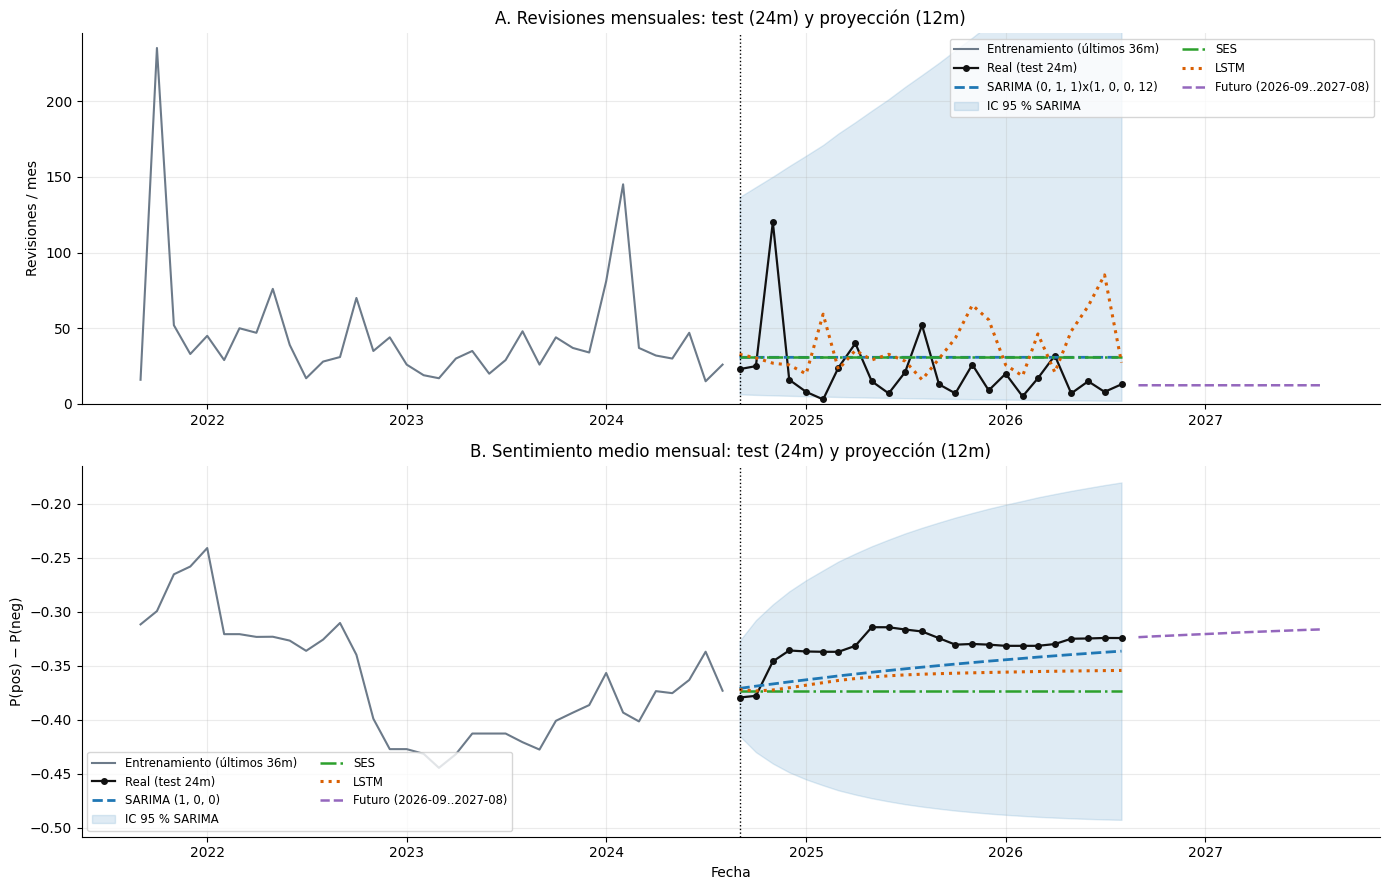

In [14]:
# Evaluamos revisiones_total y sent_medio (test 2024-09..2026-08) y proyectamos 2026-09..2027-08
serie_rev = df_m.loc["2008-02":"2026-08", "revisiones_total"].astype(float)
serie_sent = df_m.loc["2008-02":"2026-08", "sent_medio"].astype(float)

met_rev, pred_rev, fit_rev, ord_rev, est_rev = evaluar_modelos_continuos(serie_rev, "revisiones_total", horizonte=24, log_transform=True)
met_sent, pred_sent, fit_sent, ord_sent, est_sent = evaluar_modelos_continuos(serie_sent, "sent_medio", horizonte=24, log_transform=False)

display(met_rev.sort_values(["modo", "MAE"]))
display(met_sent.sort_values(["modo", "MAE"]))

# Reentrenamos sobre toda la serie reutilizando los órdenes ganadores
trend_rev_full = "c" if (ord_rev[1] == 0 and est_rev[1] == 0) else "n"
fit_rev_full = SARIMAX(
    np.log1p(serie_rev), order=ord_rev, seasonal_order=est_rev, trend=trend_rev_full,
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)
fc_rev_fut = fit_rev_full.get_forecast(steps=12)
ci_rev_fut = np.asarray(fc_rev_fut.conf_int(alpha=0.05))

trend_sent_full = "c" if (ord_sent[1] == 0 and est_sent[1] == 0) else "n"
fit_sent_full = SARIMAX(
    serie_sent, order=ord_sent, seasonal_order=est_sent, trend=trend_sent_full,
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)
fc_sent_fut = fit_sent_full.get_forecast(steps=12)
ci_sent_fut = np.asarray(fc_sent_fut.conf_int(alpha=0.05))

# Ljung-Box (lag=12) en los modelos completos
res_rev_full = fit_rev_full.resid.iloc[1:] if ord_rev[1] > 0 else fit_rev_full.resid
res_sent_full = fit_sent_full.resid.iloc[1:] if ord_sent[1] > 0 else fit_sent_full.resid
lb_rev_full = acorr_ljungbox(res_rev_full, lags=[12], return_df=True).loc[12]
lb_sent_full = acorr_ljungbox(res_sent_full, lags=[12], return_df=True).loc[12]
print(f"Ljung-Box (lag 12) serie completa — revisiones: stat={lb_rev_full['lb_stat']:.3f}, p={lb_rev_full['lb_pvalue']:.4f}")
print(f"Ljung-Box (lag 12) serie completa — sent_medio: stat={lb_sent_full['lb_stat']:.3f}, p={lb_sent_full['lb_pvalue']:.4f}")

idx_fut = pd.date_range(serie_rev.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
fut_df = pd.DataFrame({
    "mes": idx_fut.strftime("%Y-%m"),
    "rev_pred": np.round(np.maximum(np.expm1(fc_rev_fut.predicted_mean.to_numpy()), 0), 2),
    "rev_inf95": np.round(np.maximum(np.expm1(ci_rev_fut[:, 0]), 0), 2),
    "rev_sup95": np.round(np.maximum(np.expm1(ci_rev_fut[:, 1]), 0), 2),
    "sent_pred": np.round(fc_sent_fut.predicted_mean.to_numpy(), 4),
    "sent_inf95": np.round(ci_sent_fut[:, 0], 4),
    "sent_sup95": np.round(ci_sent_fut[:, 1], 4),
})
fut_df.to_csv(RESULTS_DIR / "pronostico_futuro_12m.csv", index=False)
print(f"Pronóstico futuro: {fut_df['mes'].iloc[0]} a {fut_df['mes'].iloc[-1]} ({len(fut_df)} meses)")
display(fut_df)

# Gráfico 04: Predicciones en test (24m) y pronóstico futuro (12m)
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

train_rev_vis = serie_rev.iloc[-60:-24]
axes[0].plot(train_rev_vis.index, train_rev_vis.values, color="#6c7a89", label="Entrenamiento (últimos 36m)")
axes[0].plot(pred_rev["fecha"], pred_rev["real"], "o-", color="#111111", markersize=4, linewidth=1.6, label="Real (test 24m)")
axes[0].plot(pred_rev["fecha"], pred_rev["SARIMA_multi"], "--", color="#1f77b4", linewidth=2, label=f"SARIMA {ord_rev}x{est_rev}")
axes[0].fill_between(pred_rev["fecha"], pred_rev["SARIMA_inf95"], pred_rev["SARIMA_sup95"], color="#1f77b4", alpha=0.14, label="IC 95 % SARIMA")
axes[0].plot(pred_rev["fecha"], pred_rev["ETS_SES_multi"], "-.", color="#2ca02c", linewidth=1.8, label="SES")
axes[0].plot(pred_rev["fecha"], pred_rev["LSTM_multi"], ":", color="#d95f02", linewidth=2.2, label="LSTM")
axes[0].plot(idx_fut, fut_df["rev_pred"], "--", color="#9467bd", linewidth=1.8, label=f"Futuro ({fut_df['mes'].iloc[0]}..{fut_df['mes'].iloc[-1]})")
axes[0].axvline(pred_rev["fecha"].iloc[0], color="black", linestyle=":", linewidth=1)
axes[0].set_title("A. Revisiones mensuales: test (24m) y proyección (12m)")
axes[0].set_ylabel("Revisiones / mes")
axes[0].set_ylim(0, 245)
axes[0].legend(loc="upper right", ncol=2, fontsize=8.4)

train_sent_vis = serie_sent.iloc[-60:-24]
axes[1].plot(train_sent_vis.index, train_sent_vis.values, color="#6c7a89", label="Entrenamiento (últimos 36m)")
axes[1].plot(pred_sent["fecha"], pred_sent["real"], "o-", color="#111111", markersize=4, linewidth=1.6, label="Real (test 24m)")
axes[1].plot(pred_sent["fecha"], pred_sent["SARIMA_multi"], "--", color="#1f77b4", linewidth=2, label=f"SARIMA {ord_sent}")
axes[1].fill_between(pred_sent["fecha"], pred_sent["SARIMA_inf95"], pred_sent["SARIMA_sup95"], color="#1f77b4", alpha=0.14, label="IC 95 % SARIMA")
axes[1].plot(pred_sent["fecha"], pred_sent["ETS_SES_multi"], "-.", color="#2ca02c", linewidth=1.8, label="SES")
axes[1].plot(pred_sent["fecha"], pred_sent["LSTM_multi"], ":", color="#d95f02", linewidth=2.2, label="LSTM")
axes[1].plot(idx_fut, fut_df["sent_pred"], "--", color="#9467bd", linewidth=1.8, label=f"Futuro ({fut_df['mes'].iloc[0]}..{fut_df['mes'].iloc[-1]})")
axes[1].axvline(pred_sent["fecha"].iloc[0], color="black", linestyle=":", linewidth=1)
axes[1].set_title("B. Sentimiento medio mensual: test (24m) y proyección (12m)")
axes[1].set_ylabel("P(pos) − P(neg)")
axes[1].set_xlabel("Fecha")
axes[1].legend(loc="lower left", ncol=2, fontsize=8.4)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "04_modelos_pronostico_revisiones.png", dpi=200, bbox_inches="tight")
plt.show()


,serie,modo,modelo,MAE,RMSE
2,terminos_en_auge_multi,Multi-paso (2021-2024),"SARIMAX (1,0,0) + post_ipcc_13_spm",5.5707,8.5512
1,terminos_en_auge_multi,Multi-paso (2021-2024),"SARIMAX (1,0,0) + post_ipcc_11",5.6025,8.5734
7,terminos_en_auge_multi,Multi-paso (2021-2024),Baseline Media entrenamiento,5.5739,8.6457
0,terminos_en_auge_multi,Multi-paso (2021-2024),"SARIMA (1,0,0)",5.5831,8.6828
3,terminos_en_auge_multi,Multi-paso (2021-2024),"SARIMAX (1,0,0) log1p + post_ipcc_11",4.7130,9.1179
5,terminos_en_auge_multi,Multi-paso (2021-2024),RNN (LSTM PyTorch),5.0384,9.3121
4,terminos_en_auge_multi,Multi-paso (2021-2024),Suavizado Exponencial (SES),8.3412,9.5784
6,terminos_en_auge_multi,Multi-paso (2021-2024),Baseline Cero constante,4.6458,9.7820


Ljung-Box (lag 12) auge_multi       — SARIMAX+post_ipcc_11: stat=27.998, p=0.0055
Ljung-Box (lag 12) log1p(auge_multi)— SARIMAX+post_ipcc_11: stat=27.118, p=0.0074


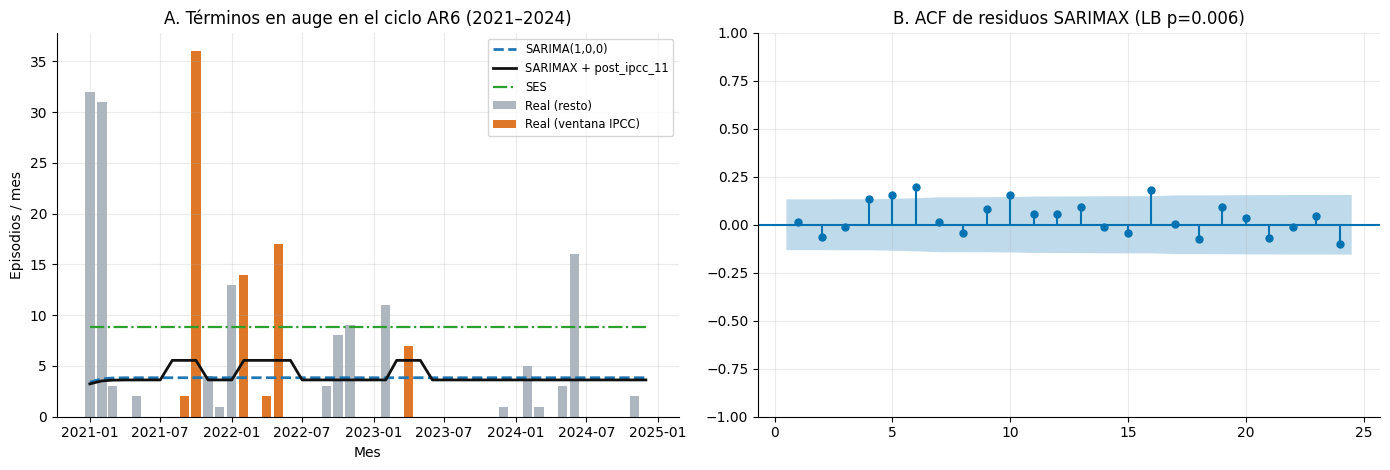

In [15]:
# Evaluamos terminos_en_auge_multi en el ciclo AR6 (2021-01 a 2024-12, 48 meses)
y_auge = df_eval["terminos_en_auge_multi"].astype(float)
tr_au = y_auge.loc[:"2020-12"]
te_au = y_auge.loc["2021-01":"2024-12"]
real_au = te_au.to_numpy(float)

m_sar_au = SARIMAX(tr_au, order=(1, 0, 0), trend="c").fit(disp=False)
p_sar_au = np.maximum(m_sar_au.get_forecast(len(te_au)).predicted_mean.to_numpy(float), 0.0)

m_sx11 = SARIMAX(tr_au, exog=df_eval.loc[tr_au.index, ["post_ipcc_11"]], order=(1, 0, 0), trend="c").fit(disp=False)
p_sx11 = np.maximum(m_sx11.get_forecast(len(te_au), exog=df_eval.loc[te_au.index, ["post_ipcc_11"]]).predicted_mean.to_numpy(float), 0.0)

m_sx13 = SARIMAX(tr_au, exog=df_eval.loc[tr_au.index, ["post_ipcc_13_spm"]], order=(1, 0, 0), trend="c").fit(disp=False)
p_sx13 = np.maximum(m_sx13.get_forecast(len(te_au), exog=df_eval.loc[te_au.index, ["post_ipcc_13_spm"]]).predicted_mean.to_numpy(float), 0.0)

# Probamos también SARIMAX sobre log1p para suavizar la asimetría y los ceros
m_sx11_log = SARIMAX(np.log1p(tr_au), exog=df_eval.loc[tr_au.index, ["post_ipcc_11"]], order=(1, 0, 0), trend="c").fit(disp=False)
p_sx11_log = np.maximum(np.expm1(m_sx11_log.get_forecast(len(te_au), exog=df_eval.loc[te_au.index, ["post_ipcc_11"]]).predicted_mean.to_numpy(float)), 0.0)

ets_au = ExponentialSmoothing(tr_au, trend=None, seasonal=None).fit()
p_ets_au = np.maximum(ets_au.forecast(len(te_au)).to_numpy(float), 0.0)

p_lstm_au_rec, _ = entrenar_y_predecir_lstm(tr_au, y_auge.loc[:"2024-12"], seq_len=12, hidden=16, epochs=250, log_transform=True)
p_zero_au = np.zeros(len(te_au))
p_mean_au = np.repeat(float(tr_au.mean()), len(te_au))

met_au = pd.DataFrame([
    calcular_metricas(real_au, p_sar_au, "terminos_en_auge_multi", "SARIMA (1,0,0)", "Multi-paso (2021-2024)"),
    calcular_metricas(real_au, p_sx11, "terminos_en_auge_multi", "SARIMAX (1,0,0) + post_ipcc_11", "Multi-paso (2021-2024)"),
    calcular_metricas(real_au, p_sx13, "terminos_en_auge_multi", "SARIMAX (1,0,0) + post_ipcc_13_spm", "Multi-paso (2021-2024)"),
    calcular_metricas(real_au, p_sx11_log, "terminos_en_auge_multi", "SARIMAX (1,0,0) log1p + post_ipcc_11", "Multi-paso (2021-2024)"),
    calcular_metricas(real_au, p_ets_au, "terminos_en_auge_multi", "Suavizado Exponencial (SES)", "Multi-paso (2021-2024)"),
    calcular_metricas(real_au, p_lstm_au_rec, "terminos_en_auge_multi", "RNN (LSTM PyTorch)", "Multi-paso (2021-2024)"),
    calcular_metricas(real_au, p_zero_au, "terminos_en_auge_multi", "Baseline Cero constante", "Multi-paso (2021-2024)"),
    calcular_metricas(real_au, p_mean_au, "terminos_en_auge_multi", "Baseline Media entrenamiento", "Multi-paso (2021-2024)"),
]).sort_values("RMSE")

metricas_todas = pd.concat([met_rev, met_sent, met_au], ignore_index=True)
metricas_todas.to_csv(RESULTS_DIR / "metricas_modelos_temporales.csv", index=False)

pred_rev.assign(serie="revisiones_total").to_csv(RESULTS_DIR / "predicciones_test.csv", index=False)
display(met_au)

# Ljung-Box de residuos sobre toda la serie evaluable
fit_full_sx11 = SARIMAX(y_auge, exog=df_eval[["post_ipcc_11"]], order=(1, 0, 0), trend="c").fit(disp=False)
fit_full_sx11_log = SARIMAX(np.log1p(y_auge), exog=df_eval[["post_ipcc_11"]], order=(1, 0, 0), trend="c").fit(disp=False)
lb_au = acorr_ljungbox(fit_full_sx11.resid, lags=[12], return_df=True).loc[12]
lb_au_log = acorr_ljungbox(fit_full_sx11_log.resid, lags=[12], return_df=True).loc[12]
print(f"Ljung-Box (lag 12) auge_multi       — SARIMAX+post_ipcc_11: stat={lb_au['lb_stat']:.3f}, p={lb_au['lb_pvalue']:.4f}")
print(f"Ljung-Box (lag 12) log1p(auge_multi)— SARIMAX+post_ipcc_11: stat={lb_au_log['lb_stat']:.3f}, p={lb_au_log['lb_pvalue']:.4f}")

# Gráfico 05: Pronóstico en ciclo AR6 y ACF de residuos
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
mask_te_post = df_eval.loc[te_au.index, "post_ipcc_11"] == 1
axes[0].bar(te_au.index[~mask_te_post], real_au[~mask_te_post], width=24, color="#9aa5b1", alpha=0.8, label="Real (resto)")
axes[0].bar(te_au.index[mask_te_post], real_au[mask_te_post], width=24, color="#d95f02", alpha=0.85, label="Real (ventana IPCC)")
axes[0].plot(te_au.index, p_sar_au, "--", color="#1f77b4", linewidth=2, label="SARIMA(1,0,0)")
axes[0].plot(te_au.index, p_sx11, "-", color="#111111", linewidth=2, label="SARIMAX + post_ipcc_11")
axes[0].plot(te_au.index, p_ets_au, "-.", color="#2ca02c", linewidth=1.6, label="SES")
axes[0].set_title("A. Términos en auge en el ciclo AR6 (2021–2024)")
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("Episodios / mes")
axes[0].legend(loc="upper right", fontsize=8.3)

plot_acf(fit_full_sx11.resid, lags=24, ax=axes[1], zero=False, title=f"B. ACF de residuos SARIMAX (LB p={lb_au['lb_pvalue']:.3f})")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "05_sarimax_hipotesis_y_auge.png", dpi=200, bbox_inches="tight")
plt.show()


**Qué vemos en las métricas y en los residuos (Sección 4):**
- **`revisiones_total`:**
  - A **1 paso adelante**, gana `SARIMA(0,1,1)x(1,0,0,12)` sobre `log1p` (`MAE = 15,1603`, `RMSE = 23,6397`), reduciendo en un 28,8 % el MAE del `Naive (t-1)` (`MAE = 21,2917`, `RMSE = 33,0221`) y superando a `LSTM` (`MAE = 18,2996`, `RMSE = 27,4533`).
  - A **24 meses**, `SARIMA` (`MAE = 18,9588`, `RMSE = 25,0564`) es el mejor de los modelos entrenados, por delante de `SES` (`MAE = 19,2607`), `Holt amortiguado` (`MAE = 19,4396`) y `LSTM` (`MAE = 27,3430`). Los baselines estacional (`MAE = 34,5000`) y media histórica (`MAE = 46,9619`) se quedan muy lejos porque no hay estacionalidad y la actividad bajó mucho tras 2022. El `Naive (último valor)` (`MAE = 15,7500`) sale favorecido porque `2024-08` ya estaba en ese nivel bajo.
  - Los residuos de SARIMA pasan el test de Ljung-Box (`lag = 12`) como ruido blanco tanto en entrenamiento (`p = 0,7092`) como en la serie completa (`stat = 9,947`, `p = 0,6206`).
- **`sent_medio`:**
  - A **1 paso adelante**, `Naive (t-1)` (`MAE = 0,0042`, `RMSE = 0,0082`), `SARIMA(1,0,0)` (`MAE = 0,0043`, `RMSE = 0,0078`) y `LSTM` (`MAE = 0,0046`, `RMSE = 0,0081`) casi empatan. Como explicamos en 2.1, que el Naive acierte tanto viene de los tramos planos en los que la entradilla no cambia (`19,56 %` de meses sin cambios y `PACF(1) = 0,9665`).
  - A **24 meses**, `SARIMA(1,0,0)` reduce el error a la mitad frente a SES y al Naive (`MAE = 0,0206`, `RMSE = 0,0228` frente a `MAE = 0,0415`, `RMSE = 0,0435`) y mejora a `LSTM` (`MAE = 0,0288`, `RMSE = 0,0303`), porque vuelve poco a poco hacia la media tras el mínimo de 2023. Sus residuos también son ruido blanco (`p = 0,6051` en train; `stat = 11,099`, `p = 0,5204` en serie completa).
- **`terminos_en_auge_multi` en `2021-01`..`2024-12`:**
  - Añadir `post_ipcc_11` a `SARIMAX(1,0,0)` apenas cambia el pronóstico: el RMSE baja de `8,6828` (SARIMA sin exógena) a `8,5734` (solo un 1,3 % menos) y el MAE sube ligeramente de `5,5831` a `5,6025` (la media de entrenamiento da `5,5739`). Con `post_ipcc_13_spm` ocurre casi lo mismo (`RMSE = 8,5512`, `MAE = 5,5707`). La versión `log1p` mejora el MAE (`4,7130`, cerca del baseline cero constante con `4,6458`), pero sube el RMSE (`9,1179`) porque se queda corta en los picos. `LSTM` (`RMSE = 9,3121`) y `SES` (`RMSE = 9,5784`) quedan detrás.
  - Además, los residuos de `SARIMAX(1,0,0) + post_ipcc_11` no son ruido blanco (`Ljung-Box lag 12`: `stat = 27,998`, `p = 0,0055` en niveles; `stat = 27,118`, `p = 0,0074` en `log1p`), lo que confirma que un AR(1) gaussiano con fechas del IPCC no logra captar los picos de reescritura.
- **Pronóstico futuro (`2026-09` a `2027-08`):** los modelos prevén que siga el nivel bajo de ediciones (`~12,35–12,37` revisiones/mes, con un intervalo al 95 % amplio que va de `[2,05; 57,56]` en `2026-09` a `[1,03; 86,81]` en `2027-08`) y un sentimiento estable alrededor de `-0,3235` a `-0,3163`.


---


## **5. Detección de anomalías y comparación de periodos**

Cerramos el análisis con dos técnicas adicionales sobre `terminos_en_auge_multi`:
1. **Detección de anomalías sobre residuos SARIMAX de `log1p(terminos_en_auge_multi)` con Z-score (MAD):** usamos `log1p` porque en conteos brutos el exceso de ceros deja el MAD casi en cero y marca demasiados meses como anómalos. Fijamos un umbral coherente de **$Z_{\text{MAD}} > 4{,}0$** (que selecciona entre el 5 % y el 10 % de los meses) y comprobamos cuántos caen dentro o fuera de las ventanas del IPCC y qué palabras entran.
2. **Comparación de periodos históricos:** contrastamos con Kruskal-Wallis los cuatro tramos editoriales (`2008–2012`, `2013–2018`, `2019–2022` y `2023–2026`).


Meses anómalos (Z_MAD > 4.0): 16 de 219 (7.3 %)
En ventana IPCC (11 inf.): 5 (31.2 %) | Fuera: 11 (68.8 %)
En ventana IPCC (13 inf. SPM): 7 (43.8 %) | Fuera: 9 (56.2 %)


,mes,terminos_en_auge_multi,revisiones_total,sent_medio,post_ipcc_11,post_ipcc_13_spm,z_mad_auge_log1p,z_mad_rev,top_terminos_multi
162,2021-10,36,235,-0.299,1,1,5.44,2.17,"adapt, forest, action"
153,2021-01,32,221,-0.375,0,0,5.25,0.78,"adaptation, risk, people"
149,2020-09,45,301,-0.436,0,0,5.13,1.30,"health, warm, result"
143,2020-03,43,212,-0.327,0,0,4.96,1.37,"impact, development, technology"
36,2011-04,22,20,-0.307,0,0,4.87,-1.13,"country, national, major"
69,2014-01,23,60,-0.213,0,0,4.72,0.97,"decade, physical, basis"
139,2019-11,23,82,-0.327,1,1,4.72,-0.28,"acidification, ocean, express"
130,2019-02,15,60,-0.330,0,0,4.65,1.21,"ecosystem, predict, appear"
43,2011-11,37,110,-0.178,0,1,4.55,0.82,"synthesis, section, uncertainty"
80,2014-12,16,53,-0.153,1,1,4.37,1.17,"ice, evidence, multiple"


Kruskal-Wallis entre periodos -> auge_multi H=40.26 (p=9.37e-09) | revisiones H=80.29 (p=2.66e-17) | sentimiento H=98.52 (p=3.23e-21)


,periodo,n_meses,rev_media,rev_mediana,auge_multi_media,auge_multi_total,sent_media,T0_media,T3_media,T4_media
0,2008–2012 (AR4 / SRREN-SREX),60,91.5,84.0,4.55,273,-0.215,0.128,0.333,0.147
1,2013–2018 (Ciclo AR5 / SR1.5),72,28.7,21.5,1.39,100,-0.261,0.162,0.408,0.087
2,2019–2022 (SRs + Ciclo AR6),48,95.8,66.0,8.21,394,-0.337,0.304,0.136,0.230
3,2023–2026 (Post-AR6),45,29.3,24.0,1.09,49,-0.362,0.316,0.222,0.301


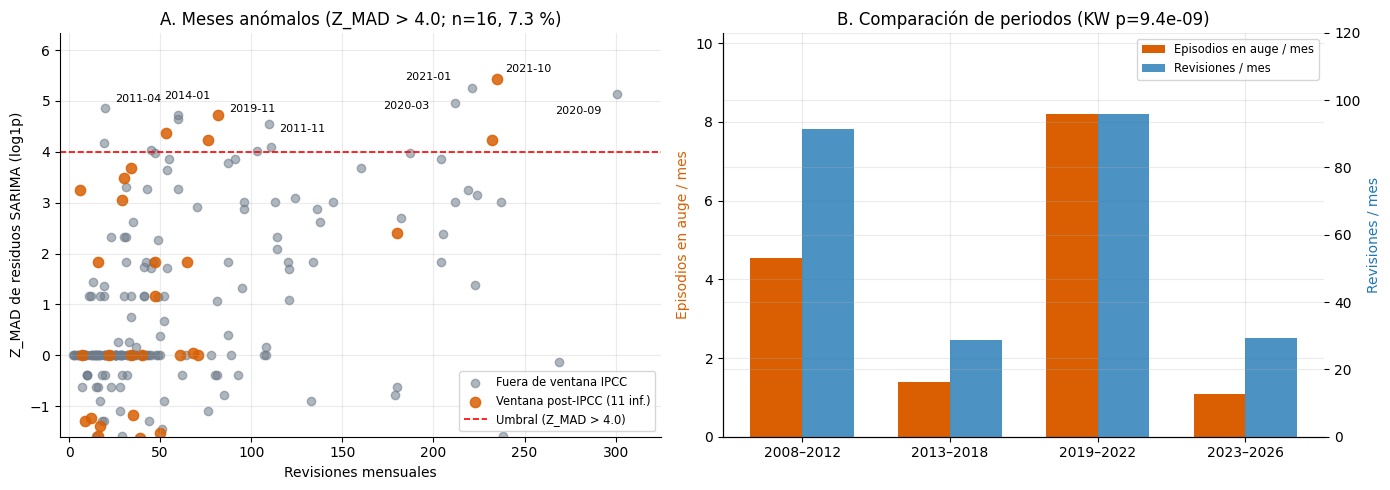

In [16]:
# Detección de anomalías usando Z_MAD > 4.0 sobre residuos SARIMAX de log1p(terminos_en_auge_multi)
UMBRAL_ZMAD = 4.0

fit_anom_au = SARIMAX(np.log1p(df_eval["terminos_en_auge_multi"]), order=(1, 0, 0), trend="c").fit(disp=False)
res_au = fit_anom_au.resid
med_au = float(np.median(res_au))
mad_au = float(np.median(np.abs(res_au - med_au)))
z_mad_au = 0.6745 * (res_au - med_au) / mad_au

fit_anom_rev = SARIMAX(np.log1p(df_eval["revisiones_total"]), order=(1, 0, 1), trend="c").fit(disp=False)
res_rev = fit_anom_rev.resid
med_rv = float(np.median(res_rev))
mad_rv = float(np.median(np.abs(res_rev - med_rv)))
z_mad_rv = 0.6745 * (res_rev - med_rv) / mad_rv

anom_df = pd.DataFrame({
    "mes": df_eval["mes"],
    "terminos_en_auge_multi": df_eval["terminos_en_auge_multi"].astype(int),
    "revisiones_total": df_eval["revisiones_total"].astype(int),
    "sent_medio": df_eval["sent_medio"].round(3),
    "post_ipcc_11": df_eval["post_ipcc_11"],
    "post_ipcc_13_spm": df_eval["post_ipcc_13_spm"],
    "z_mad_auge_log1p": np.round(z_mad_au.to_numpy(), 2),
    "z_mad_rev": np.round(z_mad_rv.to_numpy(), 2),
}).merge(pal_m_multi[["mes", "top_terminos_multi"]], on="mes", how="left")

anom_top = anom_df[anom_df["z_mad_auge_log1p"] > UMBRAL_ZMAD].sort_values("z_mad_auge_log1p", ascending=False).copy()
anom_top.to_csv(RESULTS_DIR / "anomalias_detectadas.csv", index=False)

n_anom = len(anom_top)
pct_anom = n_anom / len(anom_df) * 100
n_anom_ipcc11 = int((anom_top["post_ipcc_11"] == 1).sum())
n_anom_ipcc13 = int((anom_top["post_ipcc_13_spm"] == 1).sum())
print(f"Meses anómalos (Z_MAD > {UMBRAL_ZMAD:.1f}): {n_anom} de {len(anom_df)} ({pct_anom:.1f} %)")
print(f"En ventana IPCC (11 inf.): {n_anom_ipcc11} ({n_anom_ipcc11/n_anom*100:.1f} %) | Fuera: {n_anom - n_anom_ipcc11} ({(n_anom-n_anom_ipcc11)/n_anom*100:.1f} %)")
print(f"En ventana IPCC (13 inf. SPM): {n_anom_ipcc13} ({n_anom_ipcc13/n_anom*100:.1f} %) | Fuera: {n_anom - n_anom_ipcc13} ({(n_anom-n_anom_ipcc13)/n_anom*100:.1f} %)")
display(anom_top)

# Comparación de los 4 periodos históricos con Kruskal-Wallis
filas_per = []
for ini, fin, etiq, _ in REGIMENES:
    sub = df_m.loc[ini[:7]:fin[:7]]
    filas_per.append({
        "periodo": etiq.replace("\n", " "),
        "n_meses": len(sub),
        "rev_media": round(float(sub["revisiones_total"].mean()), 1),
        "rev_mediana": round(float(sub["revisiones_total"].median()), 1),
        "auge_multi_media": round(float(sub["terminos_en_auge_multi"].mean()), 2),
        "auge_multi_total": int(sub["terminos_en_auge_multi"].sum()),
        "sent_media": round(float(sub["sent_medio"].mean()), 3),
        "T0_media": round(float(sub["topico_0"].mean()), 3),
        "T3_media": round(float(sub["topico_3"].mean()), 3),
        "T4_media": round(float(sub["topico_4"].mean()), 3),
    })

periodos_df = pd.DataFrame(filas_per)
grupos_auge = [df_m.loc[ini[:7]:fin[:7], "terminos_en_auge_multi"].to_numpy() for ini, fin, _, _ in REGIMENES]
grupos_rev = [df_m.loc[ini[:7]:fin[:7], "revisiones_total"].to_numpy() for ini, fin, _, _ in REGIMENES]
grupos_sent = [df_m.loc[ini[:7]:fin[:7], "sent_medio"].to_numpy() for ini, fin, _, _ in REGIMENES]
h_kw_au, p_kw_au = stats.kruskal(*grupos_auge)
h_kw_rv, p_kw_rv = stats.kruskal(*grupos_rev)
h_kw_sn, p_kw_sn = stats.kruskal(*grupos_sent)
periodos_df.to_csv(RESULTS_DIR / "comparacion_periodos.csv", index=False)
print(f"Kruskal-Wallis entre periodos -> auge_multi H={h_kw_au:.2f} (p={p_kw_au:.2e}) | revisiones H={h_kw_rv:.2f} (p={p_kw_rv:.2e}) | sentimiento H={h_kw_sn:.2f} (p={p_kw_sn:.2e})")
display(periodos_df)

# Gráfico 06: Anomalías (dentro vs. fuera de ventanas IPCC) y medias por periodo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

in_ipcc = anom_df["post_ipcc_11"] == 1
axes[0].scatter(anom_df.loc[~in_ipcc, "revisiones_total"], anom_df.loc[~in_ipcc, "z_mad_auge_log1p"],
                color="#6c7a89", alpha=0.55, label="Fuera de ventana IPCC")
axes[0].scatter(anom_df.loc[in_ipcc, "revisiones_total"], anom_df.loc[in_ipcc, "z_mad_auge_log1p"],
                color="#d95f02", s=55, alpha=0.85, label="Ventana post-IPCC (11 inf.)")
axes[0].axhline(UMBRAL_ZMAD, color="red", linestyle="--", linewidth=1.2, label=f"Umbral (Z_MAD > {UMBRAL_ZMAD:.1f})")

anot_meses = ["2021-10", "2021-01", "2020-09", "2020-03", "2011-04", "2014-01", "2019-11", "2011-11"]
offsets_anom = {
    "2021-10": (6, 5),
    "2021-01": (-48, 6),
    "2020-09": (-45, -14),
    "2020-03": (-52, -4),
    "2011-04": (7, 4),
    "2014-01": (-10, 12),
    "2019-11": (8, 2),
    "2011-11": (7, -6),
}
for _, row in anom_top[anom_top["mes"].isin(anot_meses)].iterrows():
    axes[0].annotate(
        row["mes"],
        (row["revisiones_total"], row["z_mad_auge_log1p"]),
        xytext=offsets_anom[row["mes"]],
        textcoords="offset points",
        fontsize=8.0,
    )
axes[0].set_xlim(-5, 325)
axes[0].set_ylim(-1.6, float(anom_df["z_mad_auge_log1p"].max()) + 0.9)
axes[0].set_xlabel("Revisiones mensuales")
axes[0].set_ylabel("Z_MAD de residuos SARIMA (log1p)")
axes[0].set_title(f"A. Meses anómalos (Z_MAD > {UMBRAL_ZMAD:.1f}; n={n_anom}, {pct_anom:.1f} %)")
axes[0].legend(loc="lower right", fontsize=8.3)

x_pos = np.arange(len(periodos_df))
width = 0.35
ax2 = axes[1].twinx()
axes[1].bar(x_pos - width/2, periodos_df["auge_multi_media"], width, color="#d95f02", label="Episodios en auge / mes")
ax2.bar(x_pos + width/2, periodos_df["rev_media"], width, color="#1f77b4", alpha=0.8, label="Revisiones / mes")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(["2008–2012", "2013–2018", "2019–2022", "2023–2026"])
axes[1].set_ylim(0, float(periodos_df["auge_multi_media"].max()) * 1.25)
ax2.set_ylim(0, 120)
axes[1].set_ylabel("Episodios en auge / mes", color="#d95f02")
ax2.set_ylabel("Revisiones / mes", color="#1f77b4")
axes[1].set_title(f"B. Comparación de periodos (KW p={p_kw_au:.1e})")
lines1, labels1 = axes[1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[1].legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=8.3)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "06_deteccion_anomalias_y_regimenes.png", dpi=200, bbox_inches="tight")
plt.show()


**Qué nos dicen las anomalías y los periodos (Sección 5):**
- **Anomalías ($Z_{\text{MAD}} > 4{,}0$ sobre `log1p(terminos_en_auge_multi)`):** detectamos **16 meses anómalos de 219 (`7,3 %`)**. Solo **5 (`31,2 %`)** caen dentro de las ventanas de los 11 informes del IPCC (`2021-10`, `2019-11`, `2014-12`, `2019-09` y `2022-05`); los otros **11 (`68,8 %`) ocurren fuera**. Incluso ampliando a los 13 informes (`13_spm`), más de la mitad (`9` de `16`, `56,2 %`) sigue fuera.
- **Términos que entran en los picos:** los mayores picos fuera de ventanas IPCC corresponden a reescrituras internas del artículo, como `2020-09` (45 episodios, 301 revisiones: `health, warm, result`), `2020-03` (43 episodios, 212 revisiones: `impact, development, technology`), `2021-01` (32 episodios, 221 revisiones: `adaptation, risk, people`) y `2011-11` (37 episodios: `synthesis, section, uncertainty`, citas del AR4). Entre los que sí coinciden con informes del IPCC destacan `2021-10` tras AR6 WGI (`adapt, forest, action`, 36 episodios, `Z_MAD = 5,44`) y `2019-11` tras SROCC (`acidification, ocean, express`, 23 episodios, `Z_MAD = 4,72`).
- **Diferencias entre periodos (Kruskal-Wallis):** los cuatro tramos históricos son muy distintos en todos los indicadores: `terminos_en_auge_multi` (`H = 40,26`, `p = 9,37 × 10⁻⁹`), `revisiones_total` (`H = 80,29`, `p = 2,66 × 10⁻¹⁷`) y `sent_medio` (`H = 98,52`, `p = 3,23 × 10⁻²¹`). La etapa **`2019–2022`** acumula `394` episodios (`8,21` al mes y `95,8` revisiones/mes), casi la mitad de todo el histórico en solo cuatro años. En cambio, `2013–2018` (`1,39` ep/mes, `28,7` rev/mes) y `2023–2026` (`1,09` ep/mes, `29,3` rev/mes) son mucho más tranquilos, con un tono más negativo en los últimos años (`-0,362`) y mayor peso de `T0` (`0,316`) y `T4` (`0,301`).


---


## **6. Conclusiones y veredicto final**

### **Veredicto sobre la hipótesis ($H_1$)**

> **Conclusión:** **Refutamos la hipótesis $H_1$ (no podemos rechazar $H_0$).** Aunque los meses posteriores a un informe del IPCC tienen una media algo más alta de términos en auge, los tests estadísticos, la revisión de fechas y las pruebas predictivas muestran que las publicaciones del IPCC no explican de forma general cuándo se reescribe la entradilla de *Climate change*.

1. **Los tests principales no salen significativos:** con `terminos_en_auge_multi` sobre los 11 informes verificados ($K = 3$), la diferencia de `+2,700` episodios/mes (`6,071` vs. `3,372`) no llega a ser significativa ni en permutación circular (`p = 0,1324`) ni en SARIMAX sin controles (`p = 0,0978` en niveles; `p = 0,1372` en `log1p`). El único escenario que da `p < 0,05` (`13 informes con SREX SPM nov-2011`, `p = 0,0137`) es una coincidencia de fechas: las ediciones de `2011-11` empezaron el `2011-11-06` (antes del SREX SPM del `2011-11-18`) y metían citas del AR4 (2007). Al usar la fecha del informe completo de SREX (`2012-03`), la significación desaparece (`p = 0,1142` en permutación; `p = 0,1056` en SARIMAX `log1p`).
2. **Apenas ayuda a predecir:** en el periodo AR6 (`2021–2024`), meter `post_ipcc_11` en `SARIMAX(1,0,0)` solo reduce el RMSE un `1,3 %` respecto a `SARIMA(1,0,0)` sin exógena (`8,5734` frente a `8,6828`) y empeora algo el MAE (`5,6025` frente a `5,5831`).
3. **Qué sí ocurre:** hay respuestas puntuales en $\tau = +1$ tras algunos informes concretos (`SROCC 2019` con `acidification, ocean`; `AR6 WGI 2021` con `adapt, forest, action`), y al controlar por el volumen de revisiones en `log1p` el efecto roza el 5 % (`p = 0,0432`). Sin embargo, el **68,8 %** (`11/16`) de los meses anómalos —incluidos los dos picos más altos (`2020-09` con 45 episodios y `2020-03` con 43)— vienen de reescrituras internas de Wikipedia sin relación con las publicaciones del IPCC.

### **Cómo atendimos los comentarios del profesor**

| Comentario de la Entrega 2 | Qué hicimos en la Entrega 3 |
|---|---|
| **1. `terminos_en_auge` solo guardaba el pico máximo** | Creamos `terminos_en_auge_multi` con el mismo preprocesado y umbrales, agrupando semanas seguidas en episodios contiguos para evitar duplicados: **816 episodios** (frente a 594, +37,4 %) en 165 términos (p. ej., `adaptation` pasa de 1 a 4 episodios). En la Sección 3 lo comparamos lado a lado con el indicador original. |
| **2. Poca unicidad del texto (< 50 % único)** | Lo medimos en la Sección 2.1: `38,45 %` de textos únicos (`376/978`), `61,15 %` de semanas y `19,56 %` de meses sin cambios, rachas de hasta `24` semanas y `PACF(1) = 0,9665` en `sent_medio` (que explica el error tan bajo de `Naive(t-1)` a 1 paso). Por eso priorizamos datos mensuales, revisiones y episodios de cambio léxico. |
| **3. Fijar versiones en `requirements.txt`** | Generamos `requirements.txt` en la raíz con las versiones exactas (`==`) de todas las librerías usadas en las Entregas 2 y 3, junto con la nota de `en_core_web_sm==3.8.0`. |

### **Limitaciones principales**

- **Texto repetido y solo entradilla:** al trabajar únicamente con la entradilla de un artículo enciclopédico, el texto cambia poco (`61,15 %` de semanas repetidas) y el sentimiento casi no sale del tono neutro/negativo.
- **Muchos ceros en los conteos:** el `57,3 %` de ceros en `terminos_en_auge_multi` dificulta el ajuste con modelos gaussianos como SARIMAX (`Ljung-Box p = 0,0055`), algo que hemos paliado con `log1p` y permutación circular, y que podría mejorarse con modelos de conteo (Poisson o Binomial Negativa).
- **Pocos eventos y otros factores:** solo contamos con 11–13 informes del IPCC en 18 años (algunos muy seguidos entre sí) y no incluimos otros eventos que también motivan cambios en el artículo, como las cumbres COP o debates internos de los editores.
